In [1]:
import time
from collections import defaultdict
from itertools import product

import torch
from torch import nn

from pract11.Guia11Reformat.src.ClassifierMLP import ClassifierMLP
from pract11.Guia11Reformat.src.Config import Config
from pract11.Guia11Reformat.src.FashionMNISTData import FashionMNISTData
from pract11.Guia11Reformat.src.Optimizer import create_optimizer
from pract11.Guia11Reformat.src.Trainer import Trainer
from pract11.Guia11Reformat.src.Visualizer import Visualizer


def runExperiment(config, data):
    # Configuración
    device = config.setup()

    if config.show_sample:
        data.inspect_example()

    # Modelo
    torch.manual_seed(config.SEED)

    model = ClassifierMLP(
        p_dropout=config.DROPOUT_P, neuron_1=config.neuron_1, neuron_2=config.neuron_2,
    ).to(device)

    # Comprobar dimensiones
    if config.show_dimentions:
        images, labels = next(iter(data.train_loader))

        with torch.no_grad():
            classifications = model(images.to(device))

        print(f"images.shape: {images.shape}")
        print(f"labels.shape: {labels.shape}")

        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )
        print(f"Parámetros entrenables: {n_params:,}")

        print("\nDimensiones:")
        print("Entrada:", images.shape)
        print("Logits:", classifications.shape)

    # Función de pérdida y optimizador
    loss_fn = nn.CrossEntropyLoss()

    optimizer = create_optimizer(
        model=model,
        optimizer_name=config.OPTIMIZER_NAME,
        lr=config.LEARNING_RATE
    )

    print("\nOptimizador:", config.OPTIMIZER_NAME)
    print("Dropout:", config.DROPOUT_P)

    # Untrained
    if config.show_untrained:
        Visualizer.showPredictions(model, device, data)
    # Entrenamiento
    torch.cuda.reset_peak_memory_stats()

    trainer = Trainer(
        model,
        optimizer,
        loss_fn,
        device,
        config
    )
    start = time.perf_counter()
    trainer.fit(
        data.train_loader,
        data.valid_loader,
        epochs=config.EPOCHS
    )

    training_time = time.perf_counter() - start
    trainer.history["training_time"] = training_time
    print(f"Training time: {training_time:.2f} seconds\n")
    peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)
    trainer.history["GPU_max_VRAM"] = peak_memory
    print(f"Peak GPU memory: {peak_memory:.2f} MB")

    # Gráfico de pérdidas
    if config.show_loss: Visualizer.plot_history(trainer.history)

    # Evaluación final
    _, _, confusion_matrix = trainer.test(data.test_loader)

    #Trained
    if config.show_trained:
        Visualizer.showPredictions(model, device, data)
    return trainer, data, confusion_matrix


# ============================================================
# EJECUCIÓN
# ============================================================

def pre_run(expies, data):
    results_together = {}
    for title, exp in expies.items():
        results = {}
        data.reset_loader(batch_size=exp.BATCH_SIZE)  # Reset seed and batch before each experiment
        trainer, data, confusion_matrix = runExperiment(exp, data)
        results[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix}
        results_together[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix,
                                   "config": exp}
        Visualizer.showExpieResults(results)
    return results_together


data_loaders = FashionMNISTData(
    batch_size=100,
    seed=42, show_dataset_info=False,
)


def viewAftermath(results_together):
    print("\n-----------------------------------Results TOGETHER:-----------------------------------\n")

    groups = defaultdict(dict)

    for title, result in results_together.items():
        config = result["config"]

        key = (
            config.OPTIMIZER_NAME,
            config.LEARNING_RATE
        )

        groups[key][title] = result

    for key, group_results in groups.items():
        print(f"\n-----------------------------------GROUP: {key}:-----------------------------------\n")

        Visualizer.showExpieResults(group_results, show_confusion=False)
        Visualizer.showComparativeTable(group_results)
    print("\n-----------------------------------ALL:-----------------------------------\n")
    Visualizer.showComparativeTable(results_together)


# Obiamente si corremos TODAS las combinaciones tenemos 240 expies que a ~70s mins cada uno son como 5 horas entonces podemos seleccionar parametros que afectan en conjuntos seleccionar el mejor y correr los siguentes. Ejemplo batchSize es importante para Adam entonces corremos opti y batches juntos, selecccionamos el mejor y testeamos los otros.
#STD value B100 128/64 D0.2
#Selected from here ??
opti = [
    ("SGD", 0.001),
    ("SGD", 0.01),
    ("SGD", 0.1),
    ("Adam", 0.0001),
    ("Adam", 0.001),
    ("Adam", 0.01)
]

batches = [
    64,
    100,
    256,
    512
]

neurons = [
    # (64, 32),
    (128, 64),
    # (256, 128),
    # (512, 256)
]

dropout = [
    # 0,
    0.2,
    # 0.5
]


def gen_expies(opti, batches, neurons, dropout):
    expies = {}

    for (optimizer, lr), batch, (n1, n2), drop in product(
            opti, batches, neurons, dropout
    ):
        title = f"{optimizer}-{lr}/{n1}-{n2}/B{batch}/D{drop}"

        expies[title] = Config(
            lr=lr,
            dropout_p=drop,
            epochs=30,
            optimizer_name=optimizer,
            neuron1=n1,
            neuron2=n2,
            batch_size=batch,
        )
    print(f"\nExperiments: {len(expies)}\n")
    return expies


expies = gen_expies(opti, batches, neurons, dropout)


Experiments: 24




Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 64
Training time: 134.28 seconds

Peak GPU memory: 18.47 MB

Test CEL: 0.53086
Test accuracy: 80.65%

----------------- SGD-0.001/128-64/B64/D0.2 -----------------


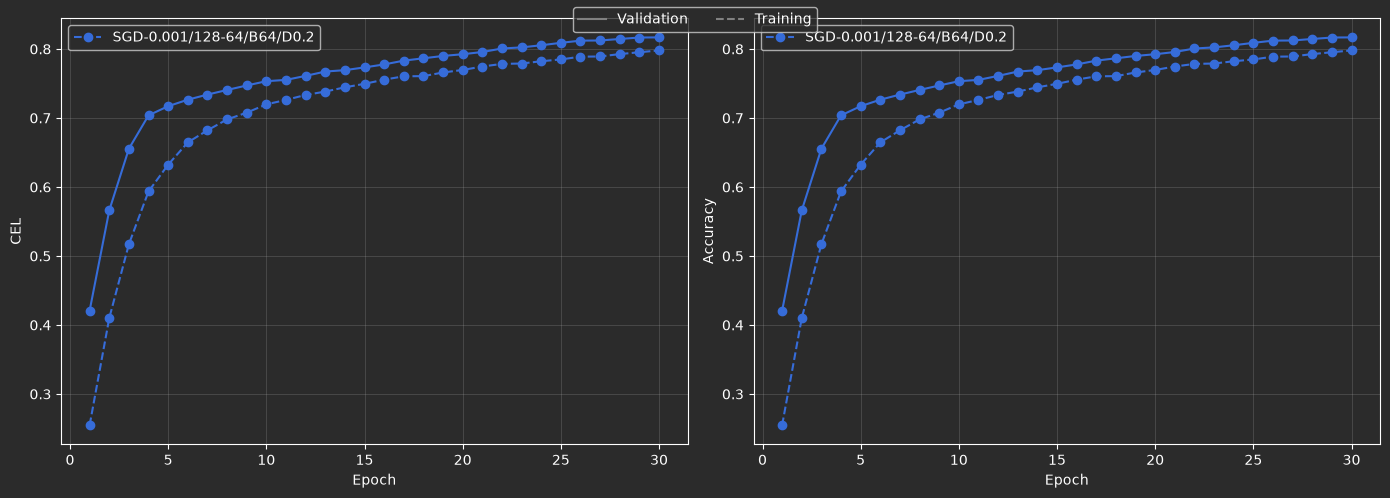

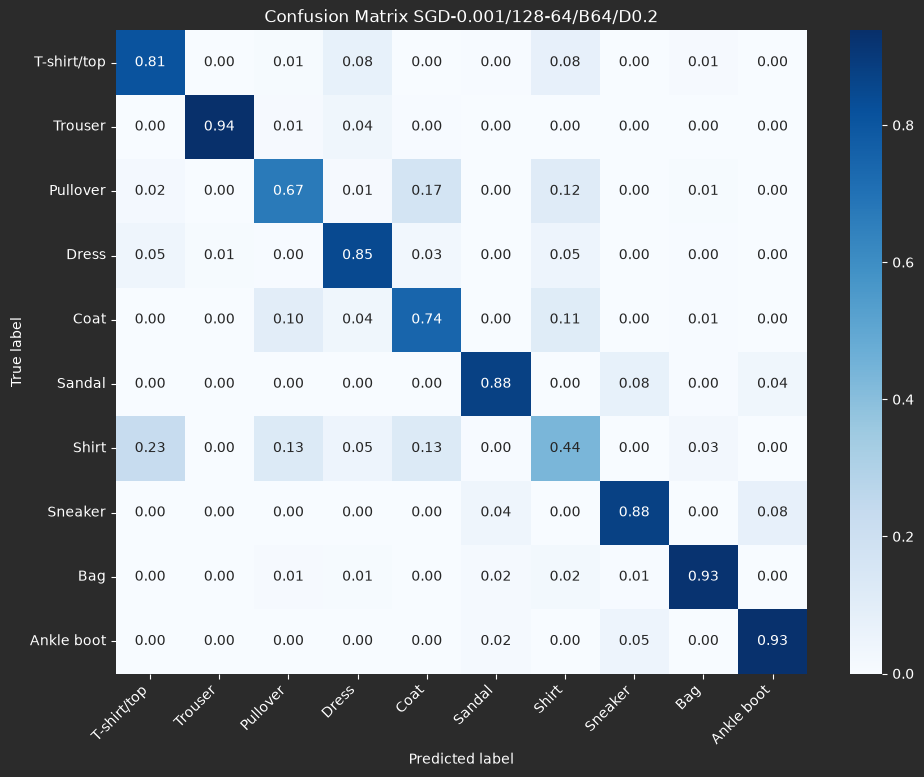


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 100
Training time: 123.45 seconds

Peak GPU memory: 19.30 MB

Test CEL: 0.59029
Test accuracy: 78.26%

----------------- SGD-0.001/128-64/B100/D0.2 -----------------


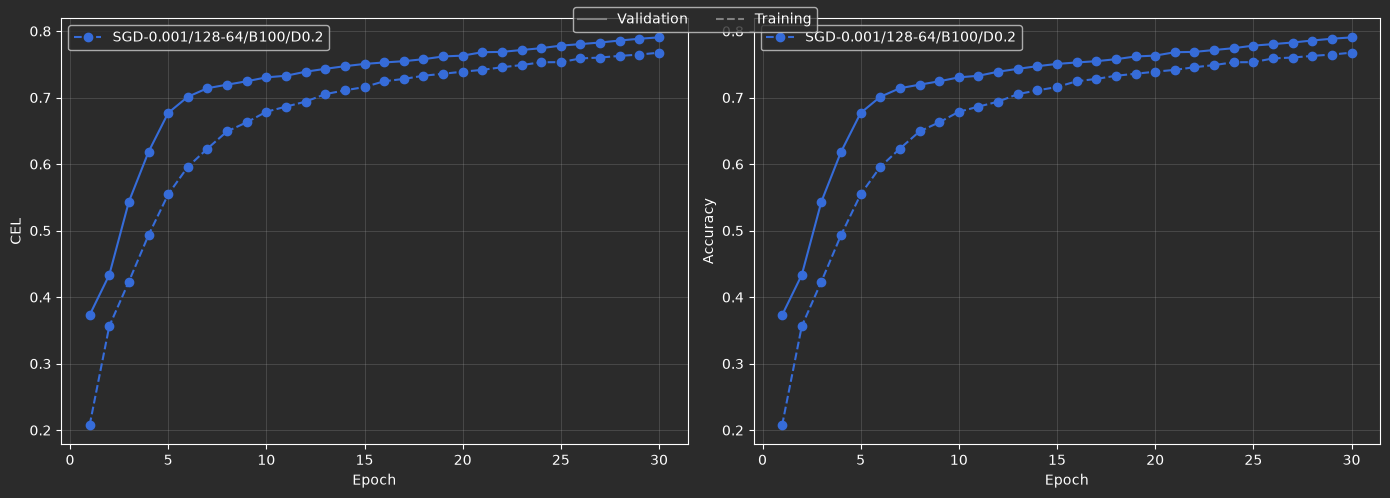

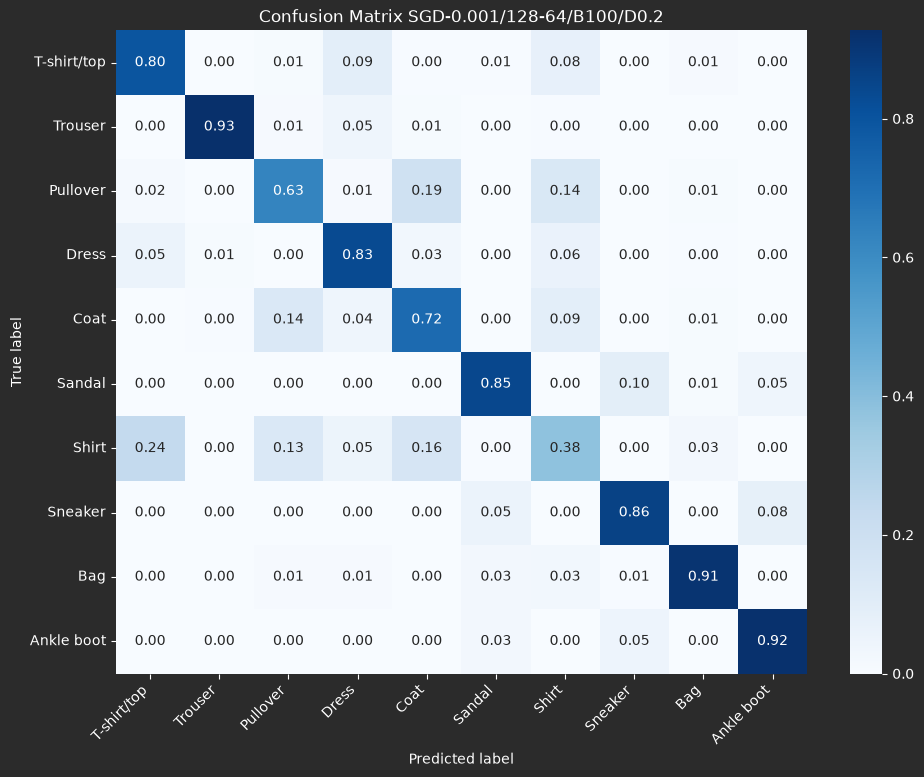


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 256
Training time: 114.61 seconds

Peak GPU memory: 20.55 MB

Test CEL: 0.75290
Test accuracy: 74.03%

----------------- SGD-0.001/128-64/B256/D0.2 -----------------


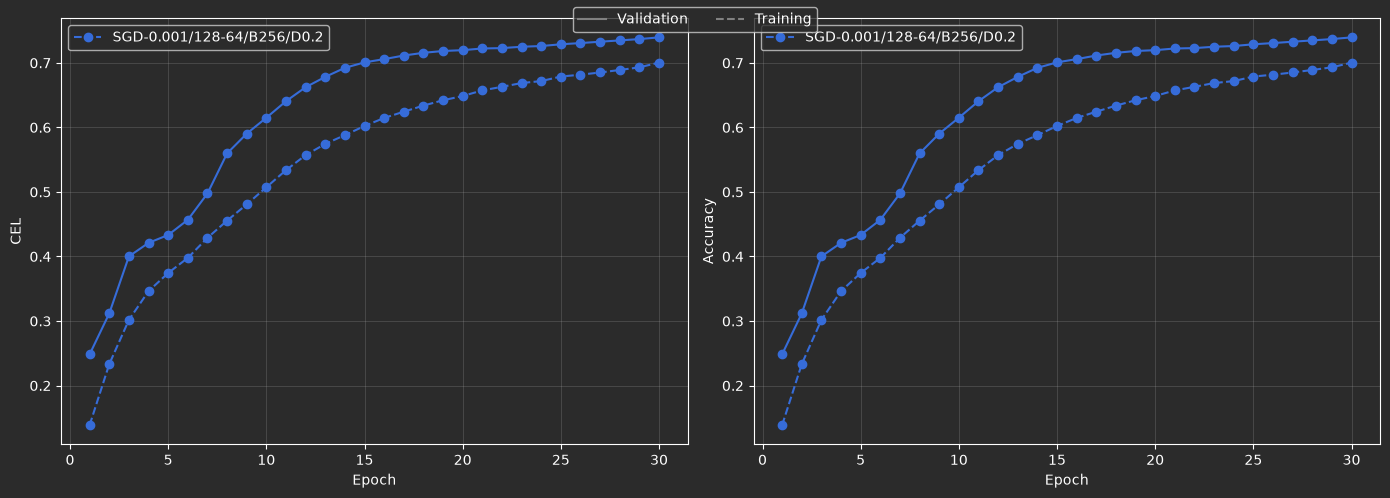

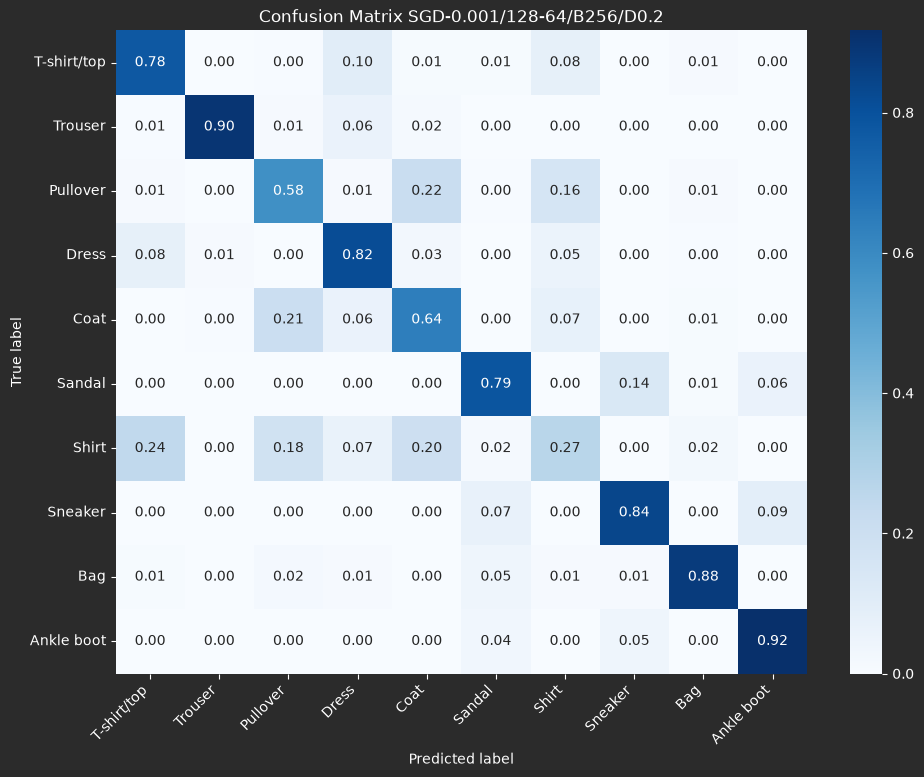


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 512
Training time: 111.88 seconds

Peak GPU memory: 22.60 MB

Test CEL: 1.06397
Test accuracy: 70.12%

----------------- SGD-0.001/128-64/B512/D0.2 -----------------


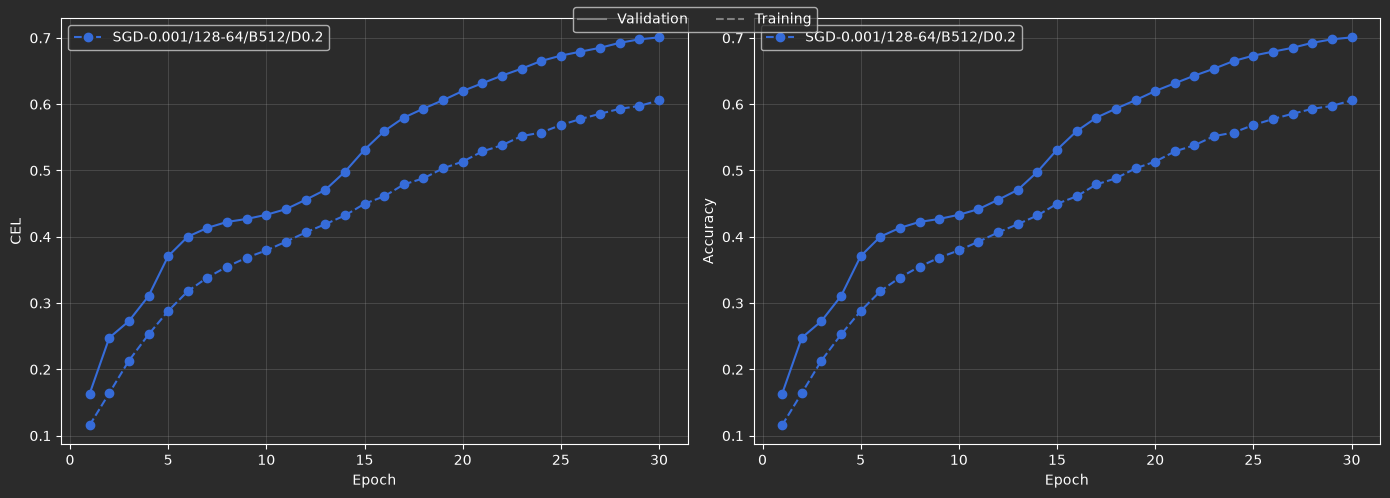

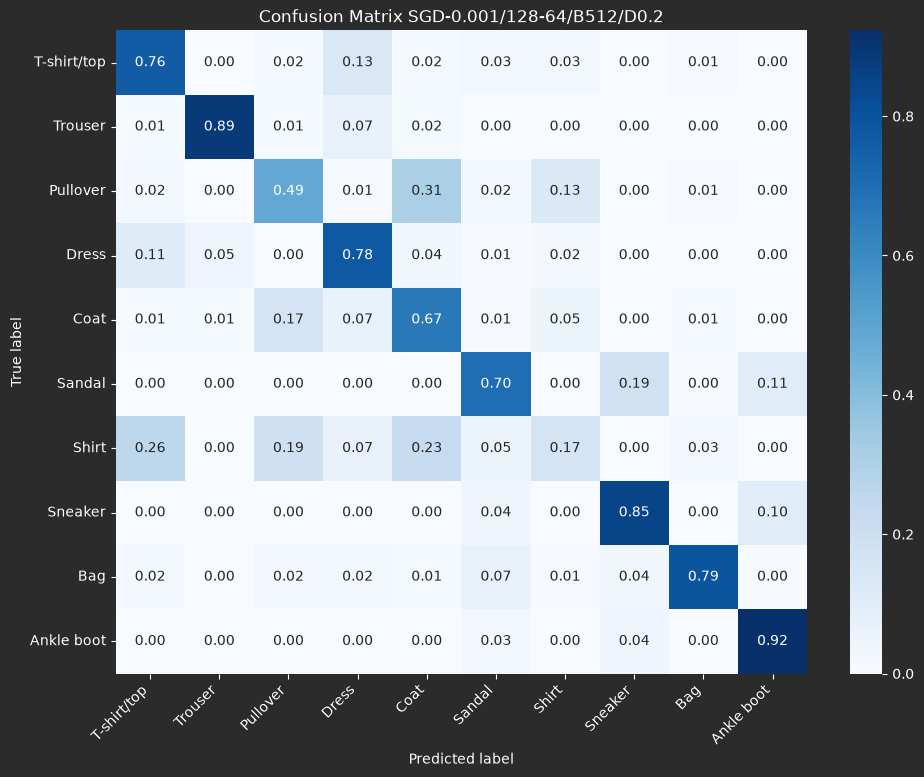


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 64
Training time: 130.81 seconds

Peak GPU memory: 21.81 MB

Test CEL: 0.35433
Test accuracy: 87.25%

----------------- SGD-0.01/128-64/B64/D0.2 -----------------


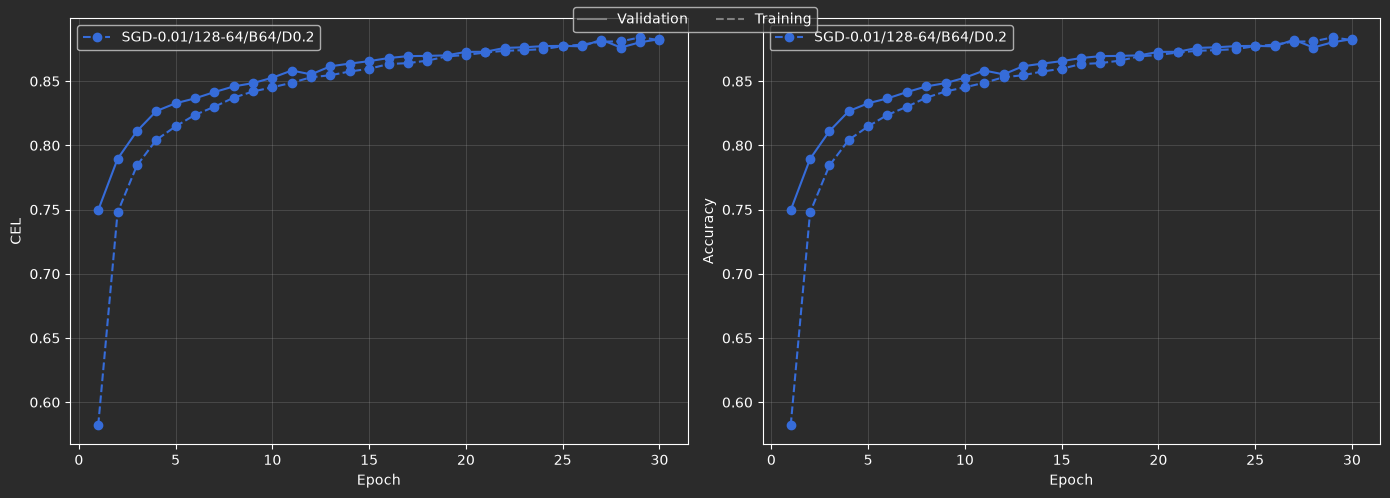

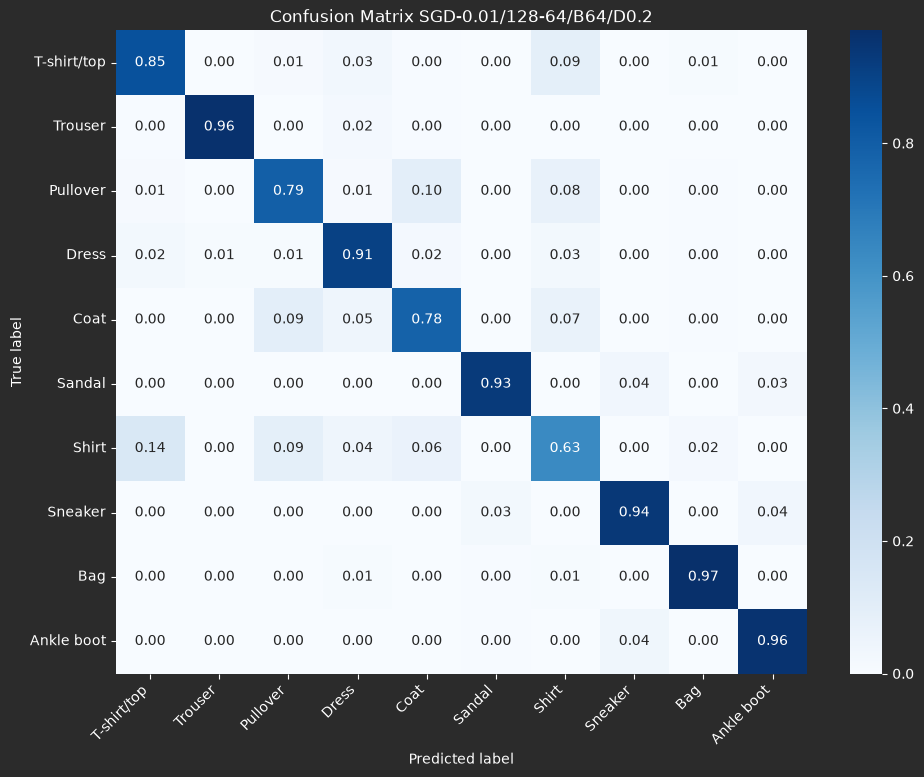


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 100
Training time: 123.52 seconds

Peak GPU memory: 22.65 MB

Test CEL: 0.37557
Test accuracy: 86.37%

----------------- SGD-0.01/128-64/B100/D0.2 -----------------


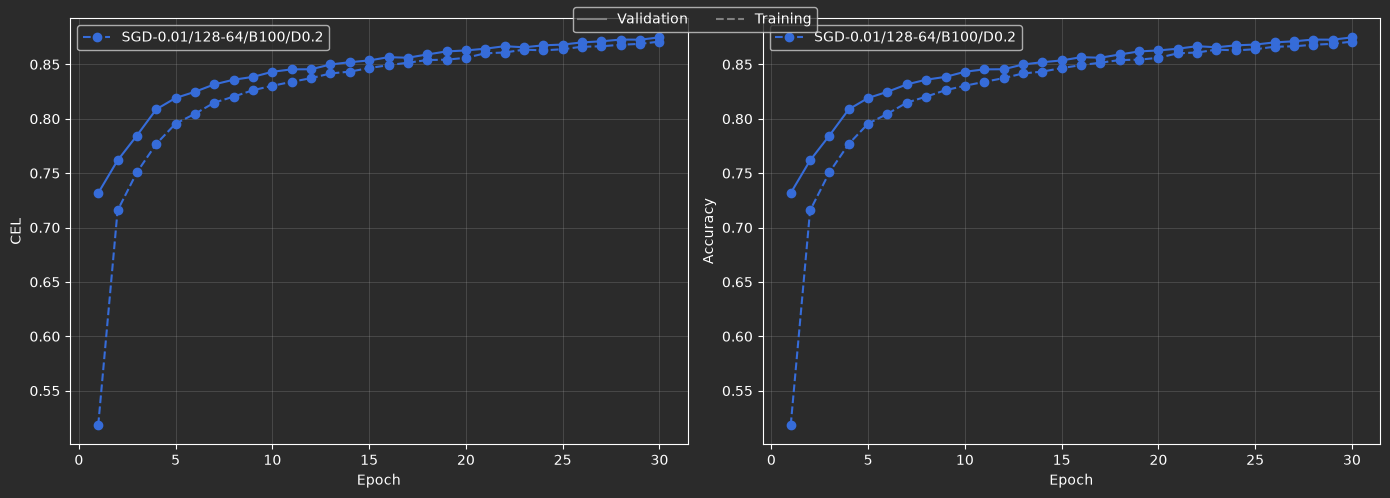

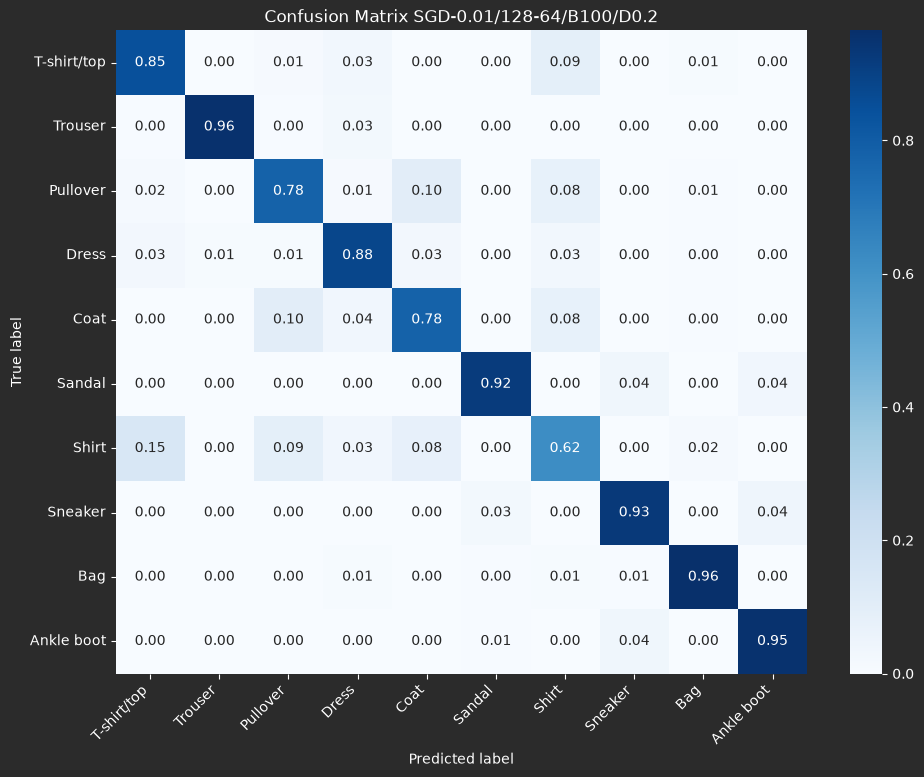


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 256
Training time: 113.36 seconds

Peak GPU memory: 23.90 MB

Test CEL: 0.43918
Test accuracy: 83.79%

----------------- SGD-0.01/128-64/B256/D0.2 -----------------


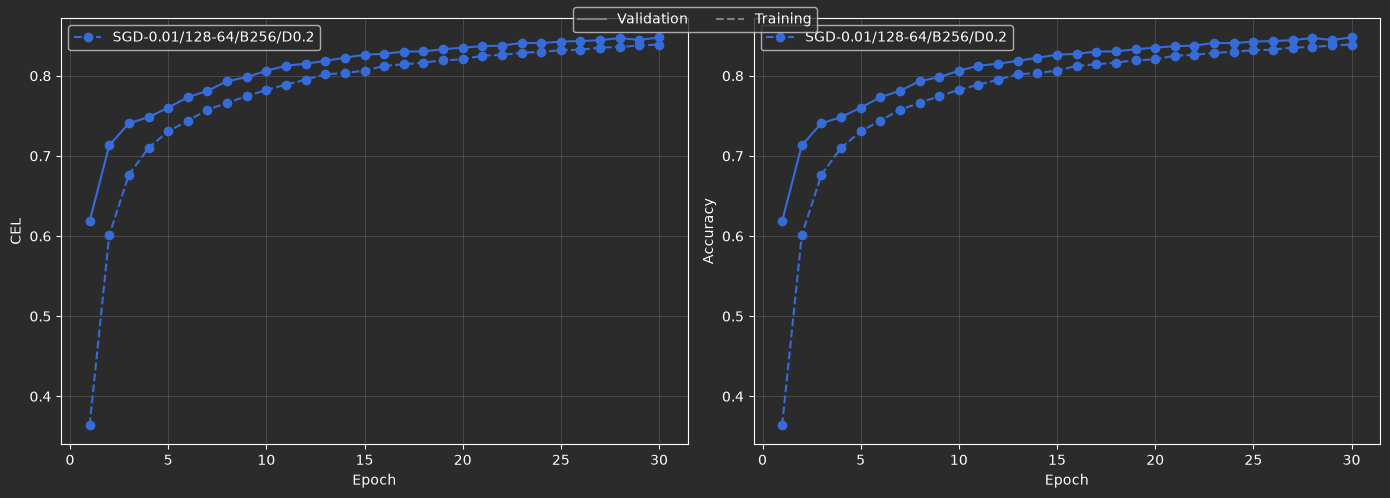

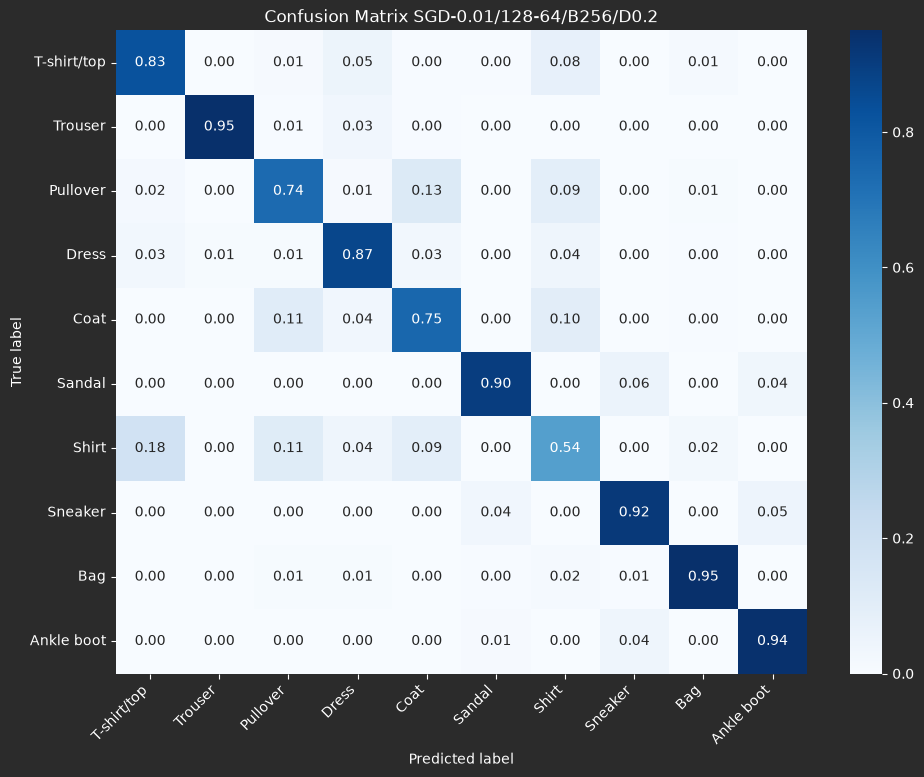


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 512
Training time: 86.58 seconds

Peak GPU memory: 25.94 MB

Test CEL: 0.50461
Test accuracy: 81.38%

----------------- SGD-0.01/128-64/B512/D0.2 -----------------


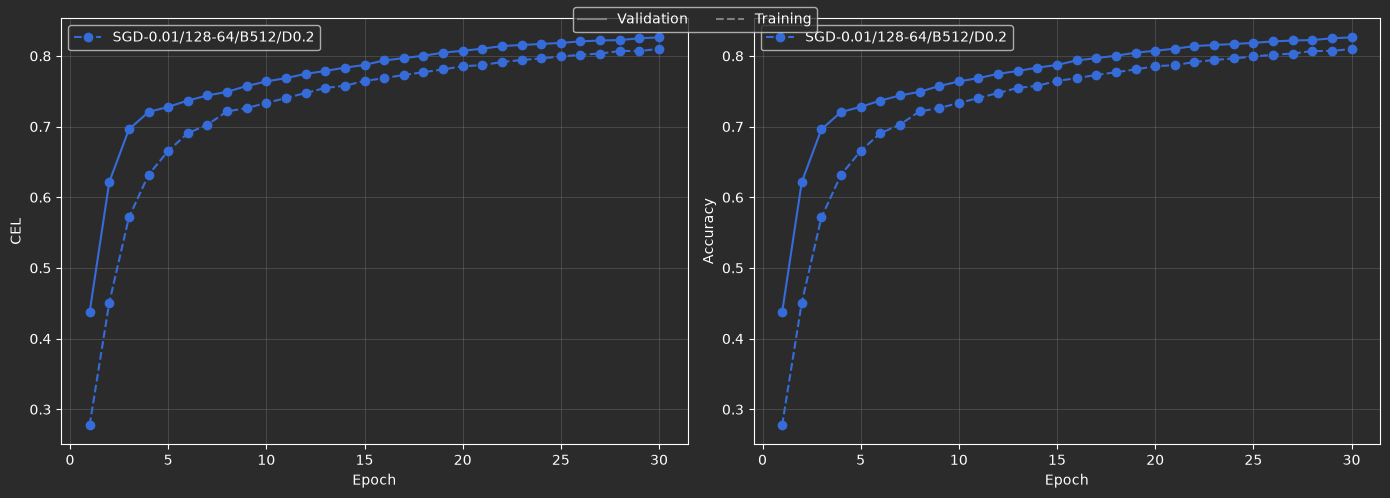

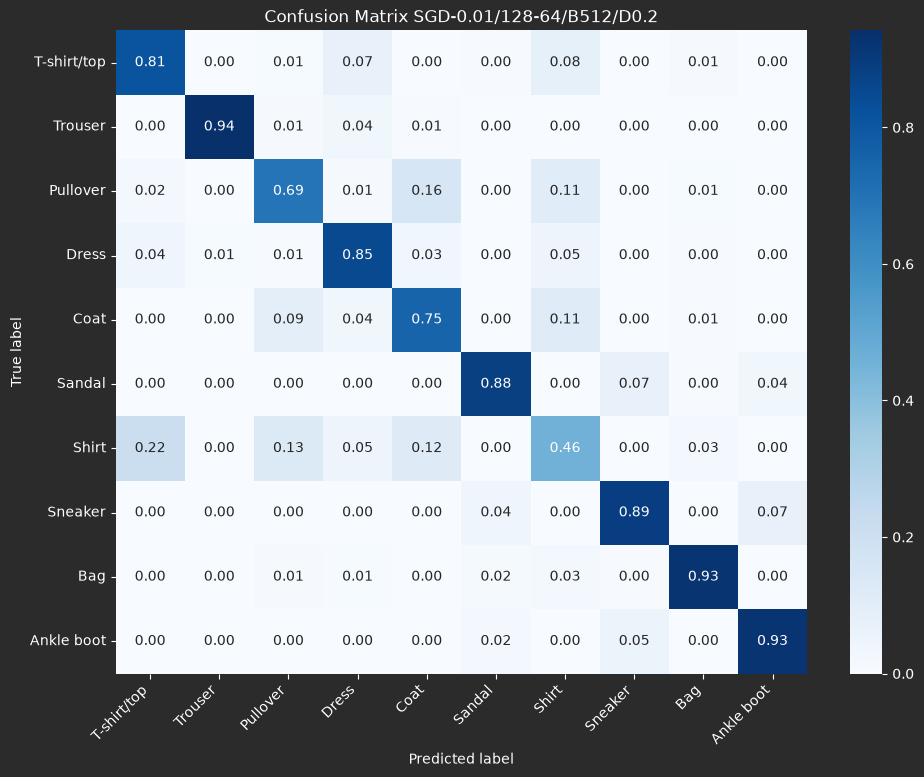


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 64
Training time: 131.36 seconds

Peak GPU memory: 25.15 MB

Test CEL: 0.33663
Test accuracy: 88.43%

----------------- SGD-0.1/128-64/B64/D0.2 -----------------


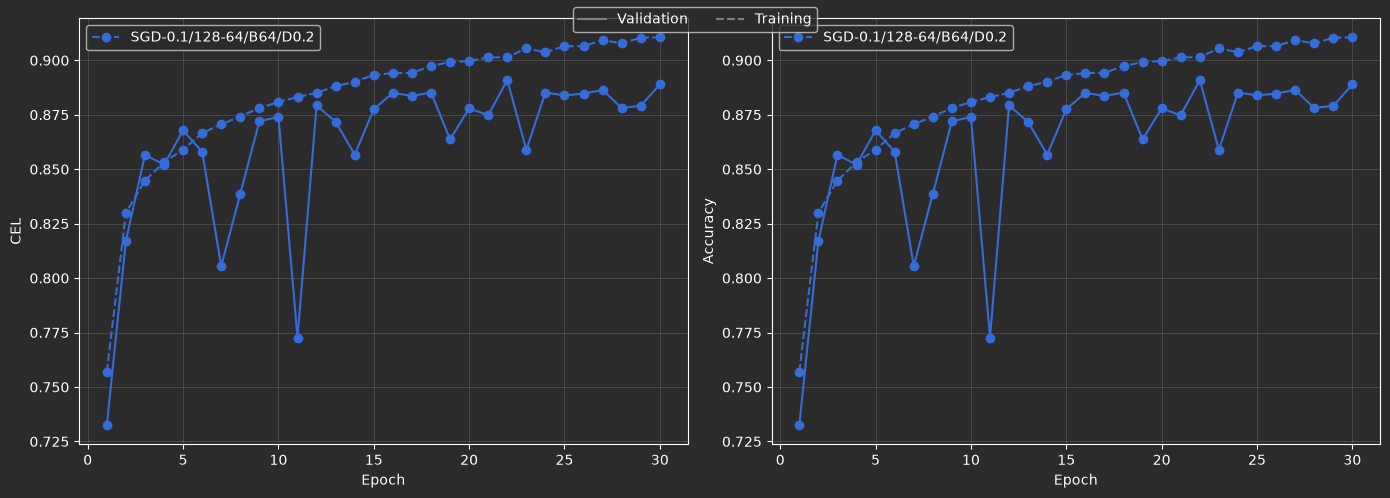

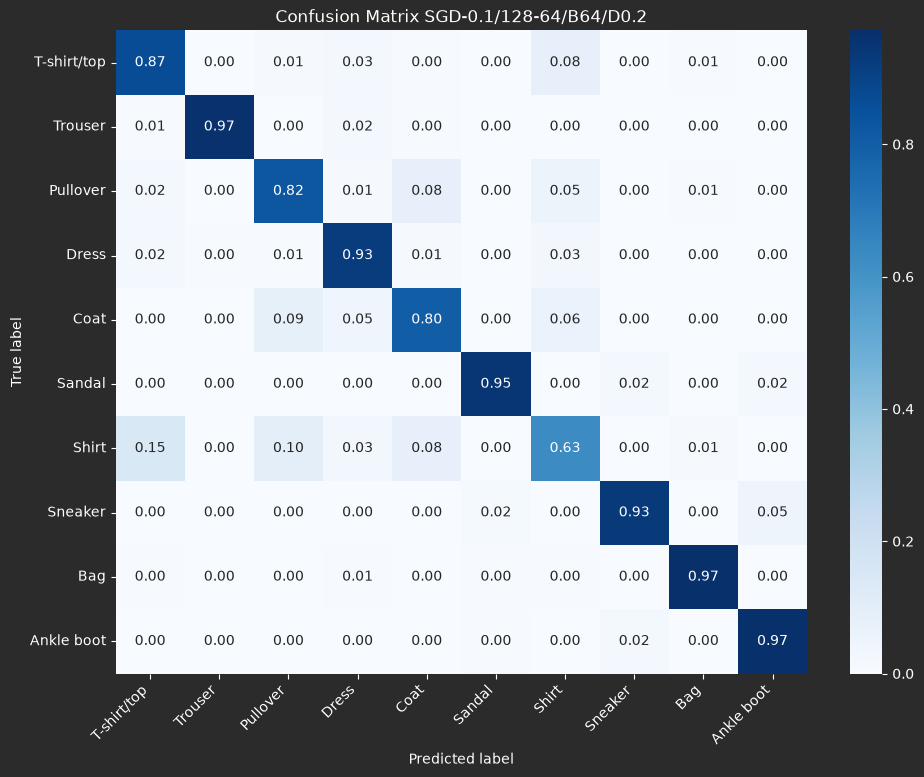


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 100
Training time: 125.54 seconds

Peak GPU memory: 25.99 MB

Test CEL: 0.32672
Test accuracy: 88.65%

----------------- SGD-0.1/128-64/B100/D0.2 -----------------


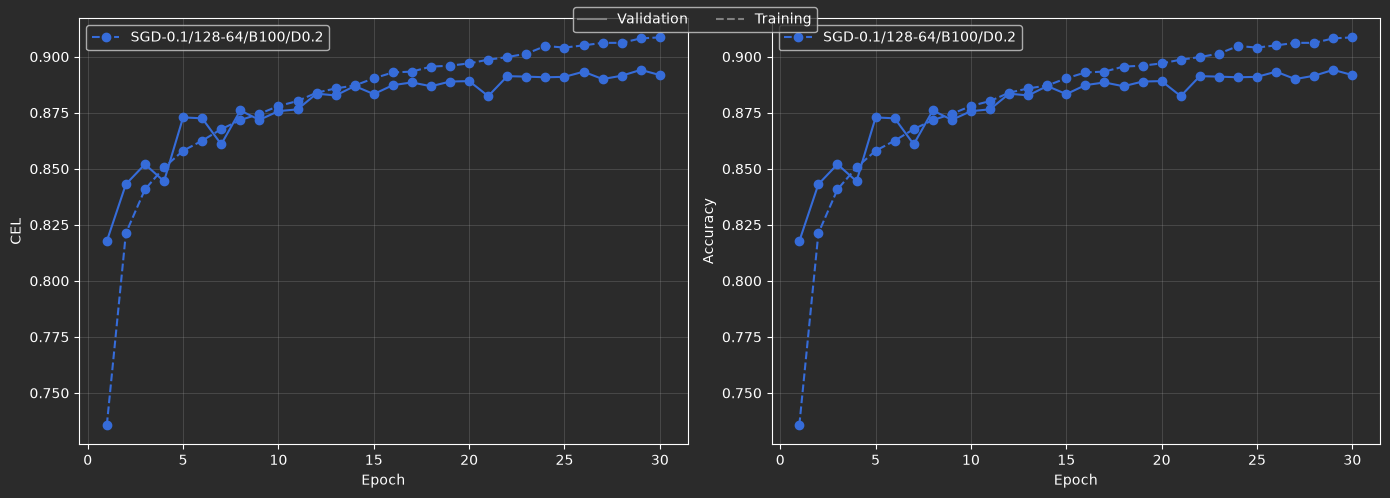

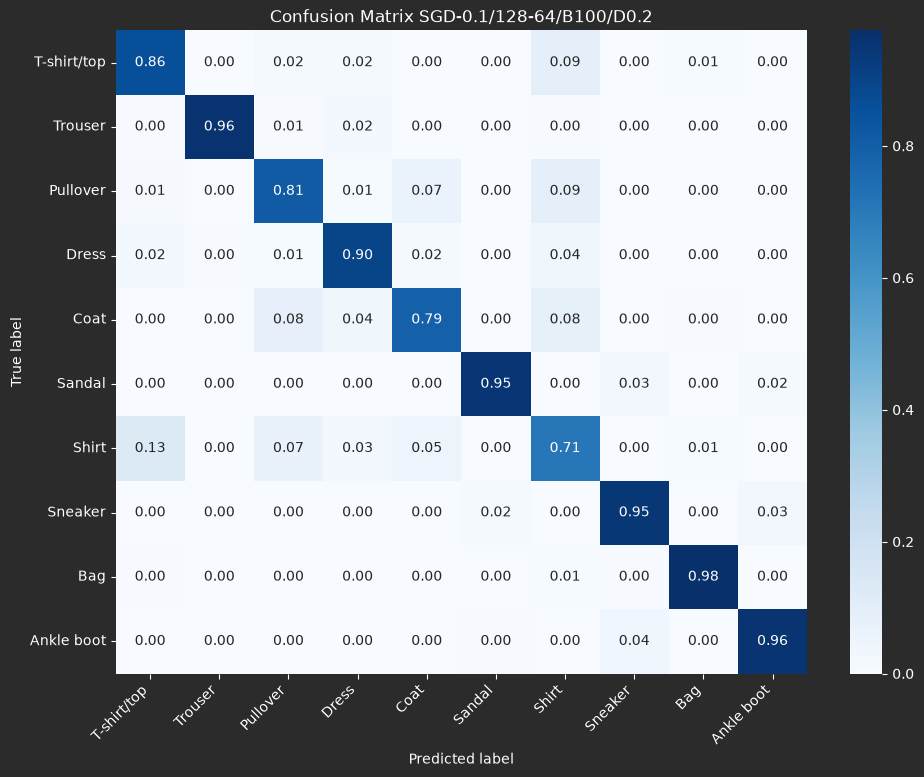


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 256
Training time: 112.89 seconds

Peak GPU memory: 27.24 MB

Test CEL: 0.35139
Test accuracy: 87.25%

----------------- SGD-0.1/128-64/B256/D0.2 -----------------


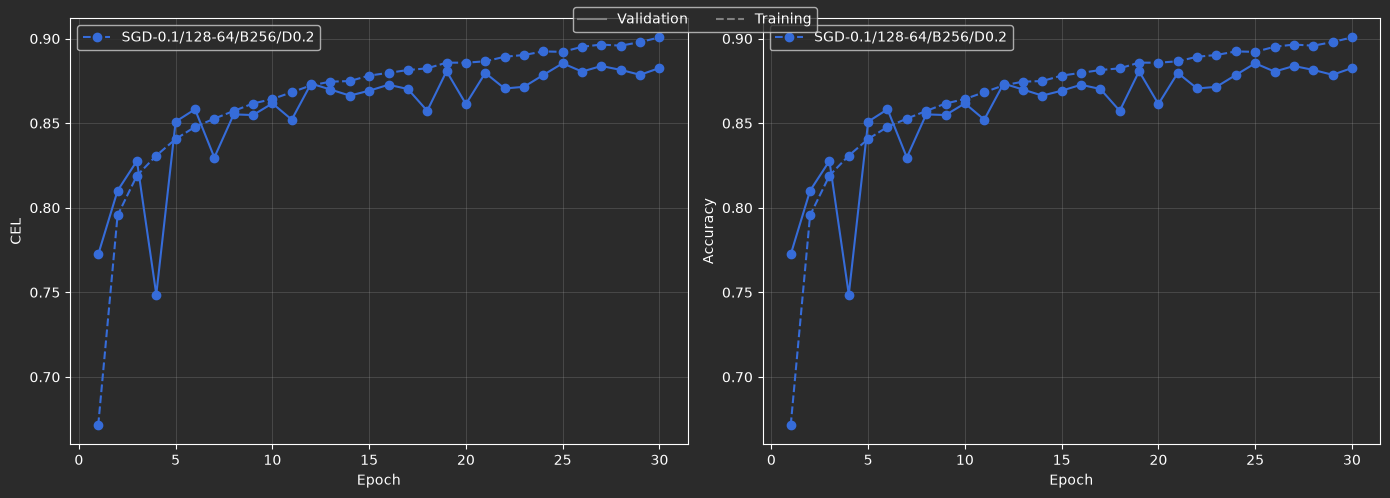

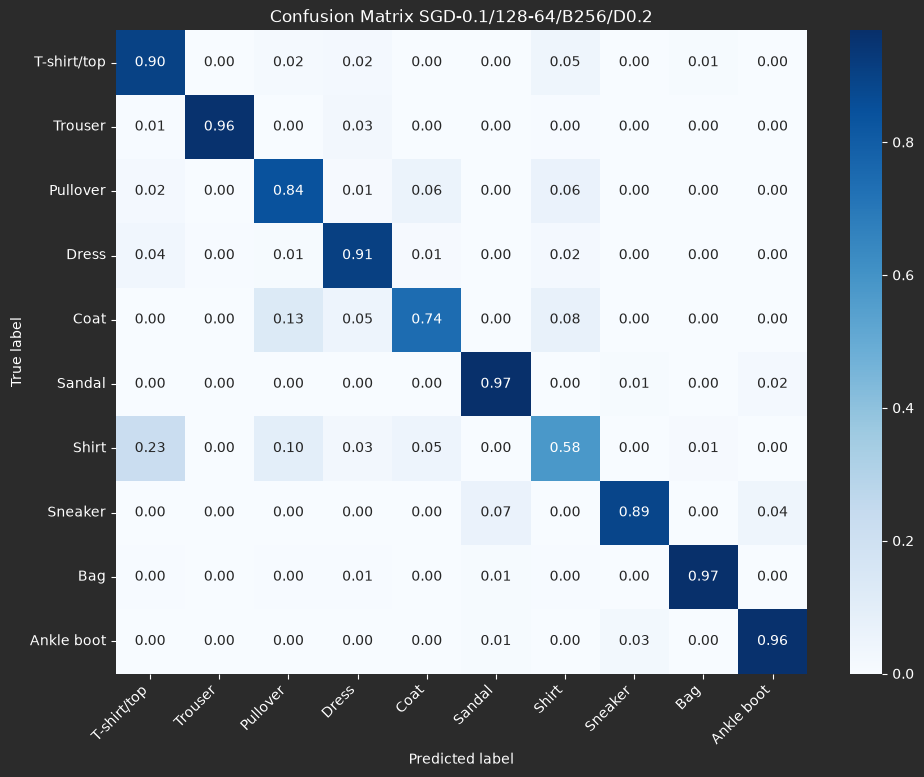


Optimizador: SGD
Dropout: 0.2

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.2 | Batch size -> 512
Training time: 111.86 seconds

Peak GPU memory: 29.29 MB

Test CEL: 0.36181
Test accuracy: 86.47%

----------------- SGD-0.1/128-64/B512/D0.2 -----------------


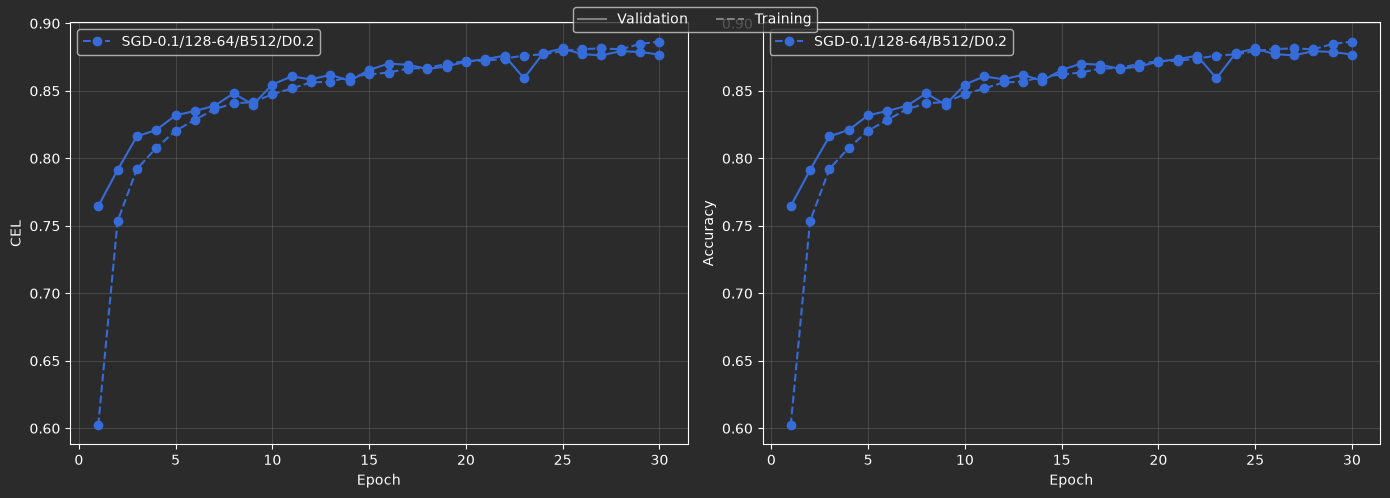

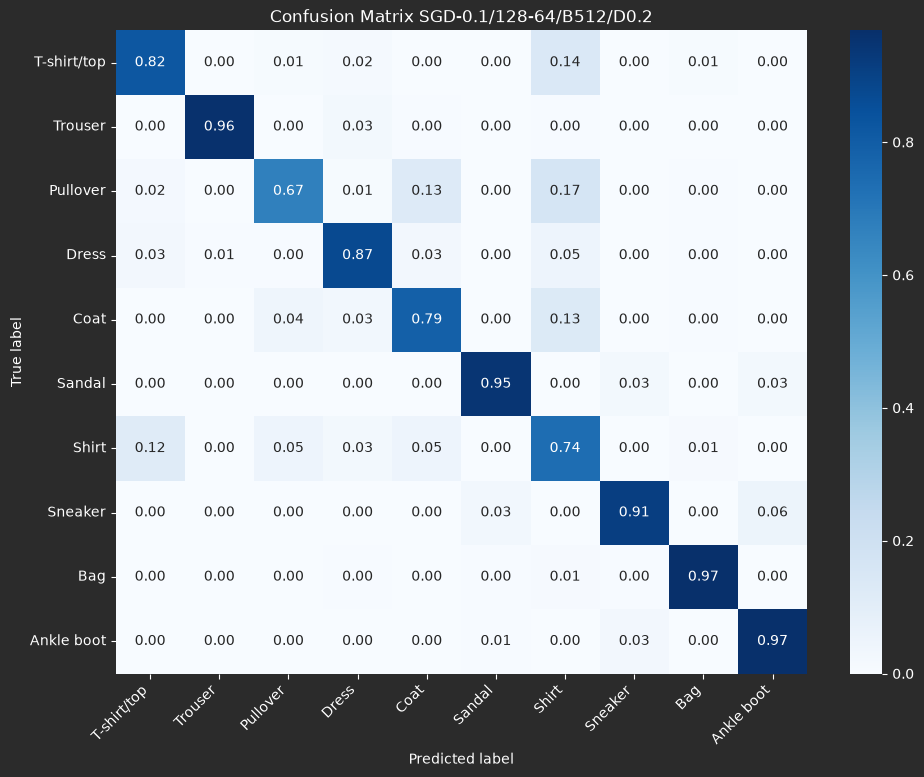


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 64
Training time: 134.14 seconds

Peak GPU memory: 29.33 MB

Test CEL: 0.33579
Test accuracy: 88.14%

----------------- Adam-0.0001/128-64/B64/D0.2 -----------------


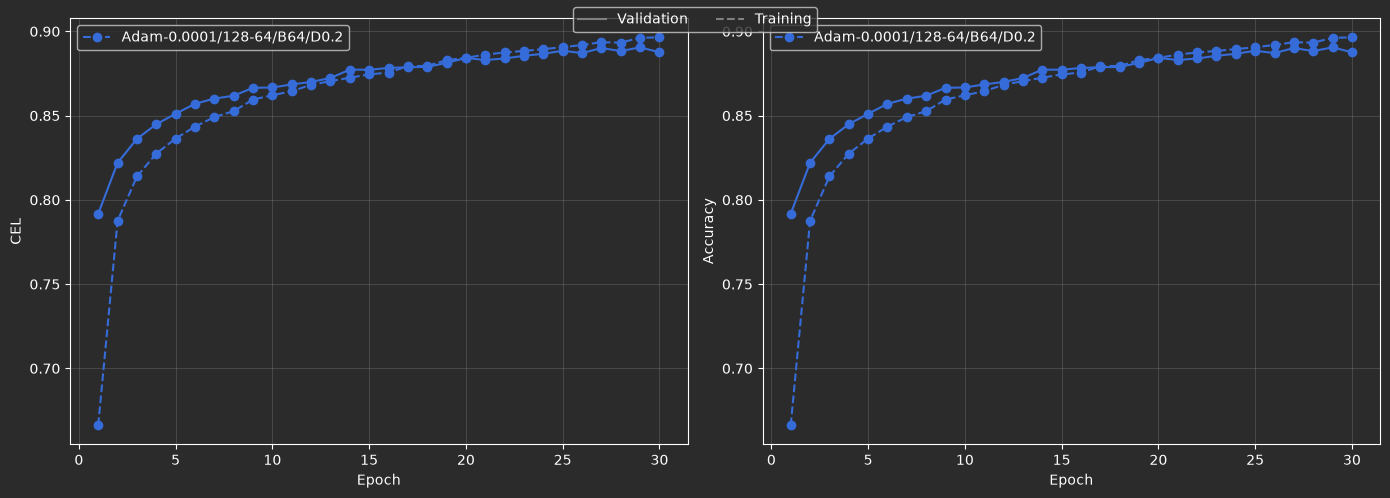

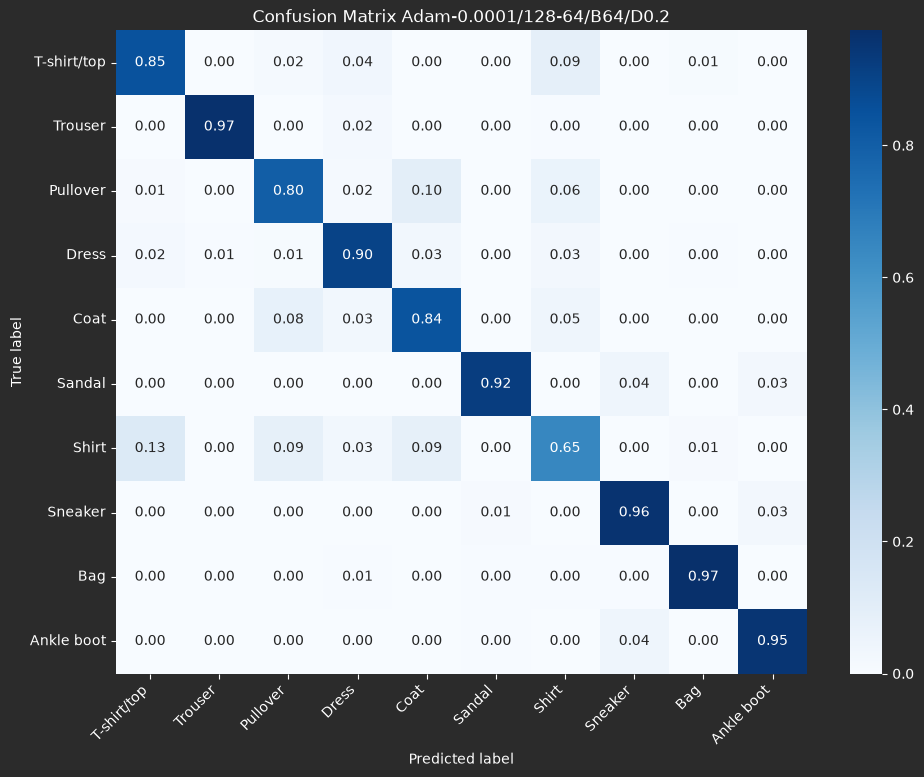


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 100
Training time: 126.44 seconds

Peak GPU memory: 31.01 MB

Test CEL: 0.33898
Test accuracy: 87.85%

----------------- Adam-0.0001/128-64/B100/D0.2 -----------------


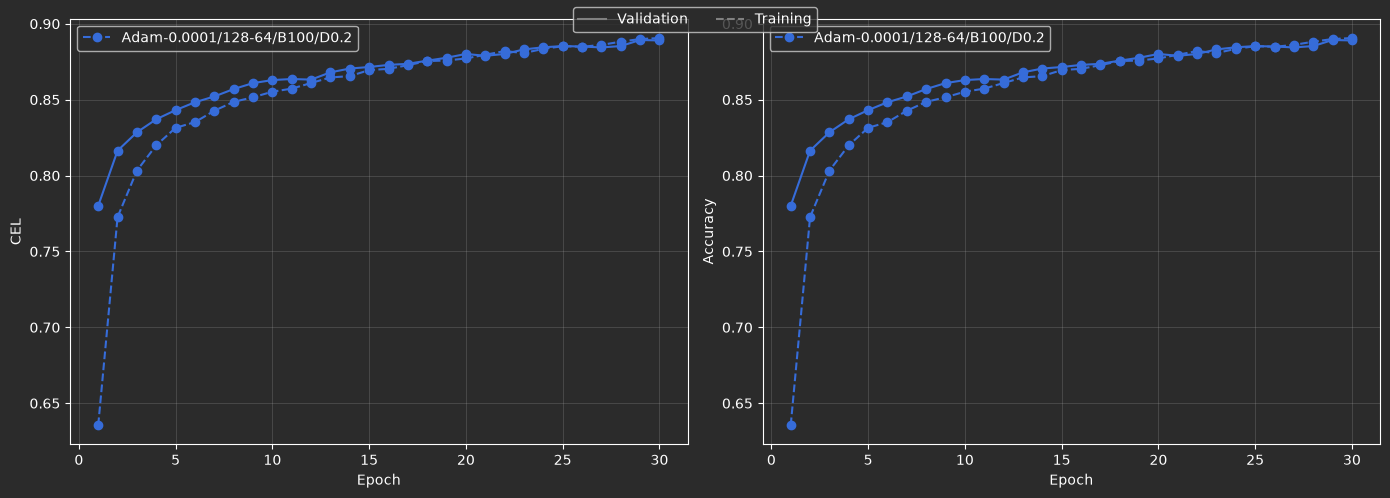

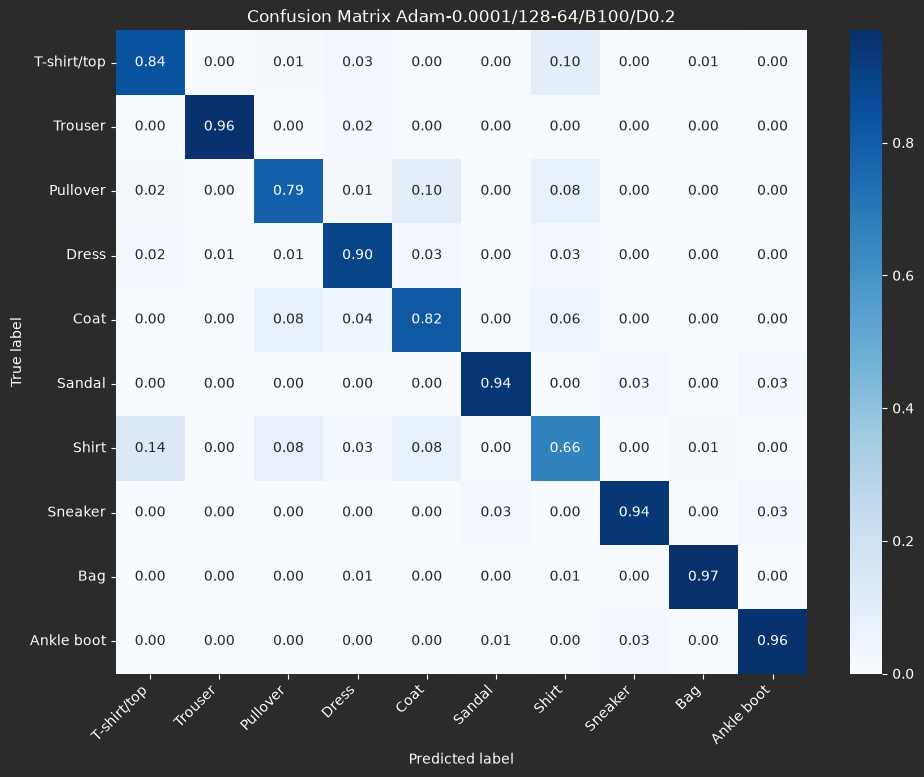


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 256
Training time: 115.80 seconds

Peak GPU memory: 33.09 MB

Test CEL: 0.36643
Test accuracy: 86.77%

----------------- Adam-0.0001/128-64/B256/D0.2 -----------------


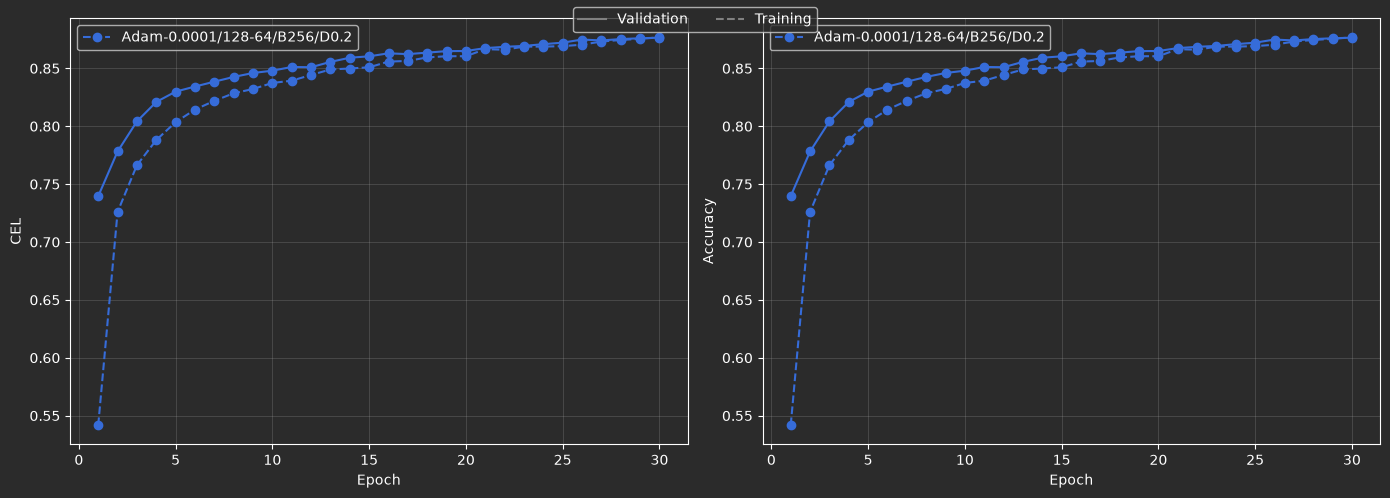

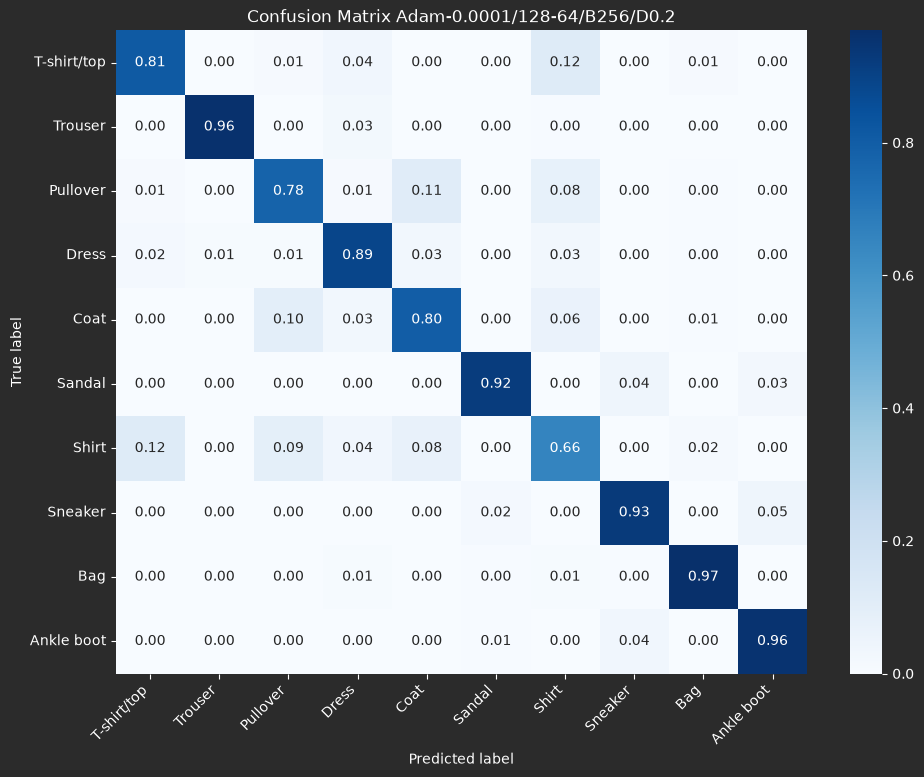


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 512
Training time: 113.50 seconds

Peak GPU memory: 35.97 MB

Test CEL: 0.39059
Test accuracy: 85.77%

----------------- Adam-0.0001/128-64/B512/D0.2 -----------------


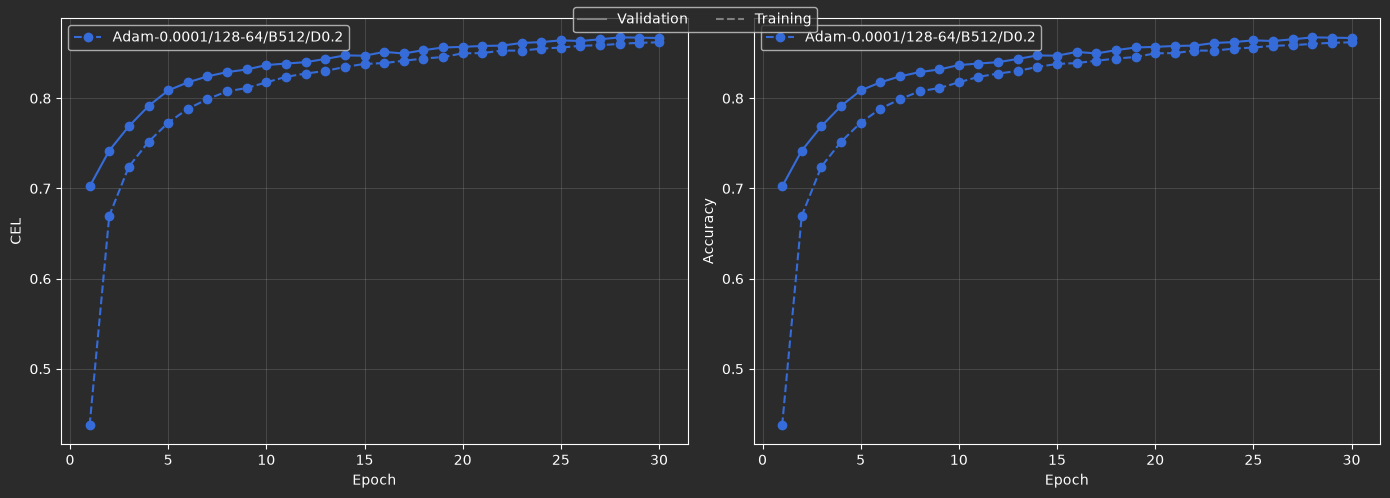

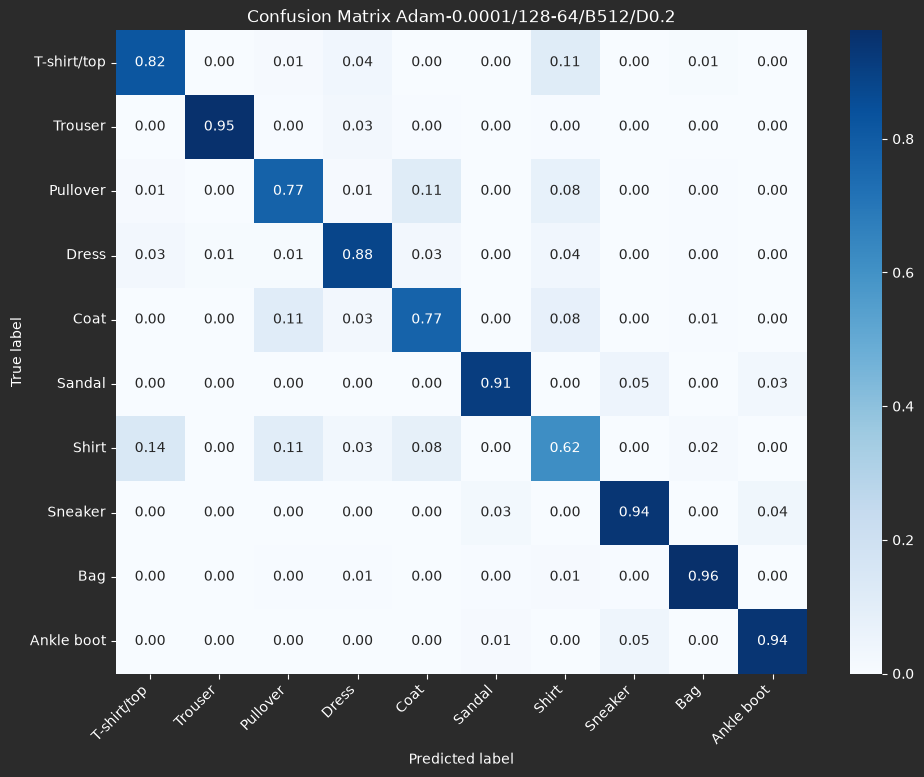


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 64
Training time: 133.72 seconds

Peak GPU memory: 36.02 MB

Test CEL: 0.35654
Test accuracy: 88.01%

----------------- Adam-0.001/128-64/B64/D0.2 -----------------


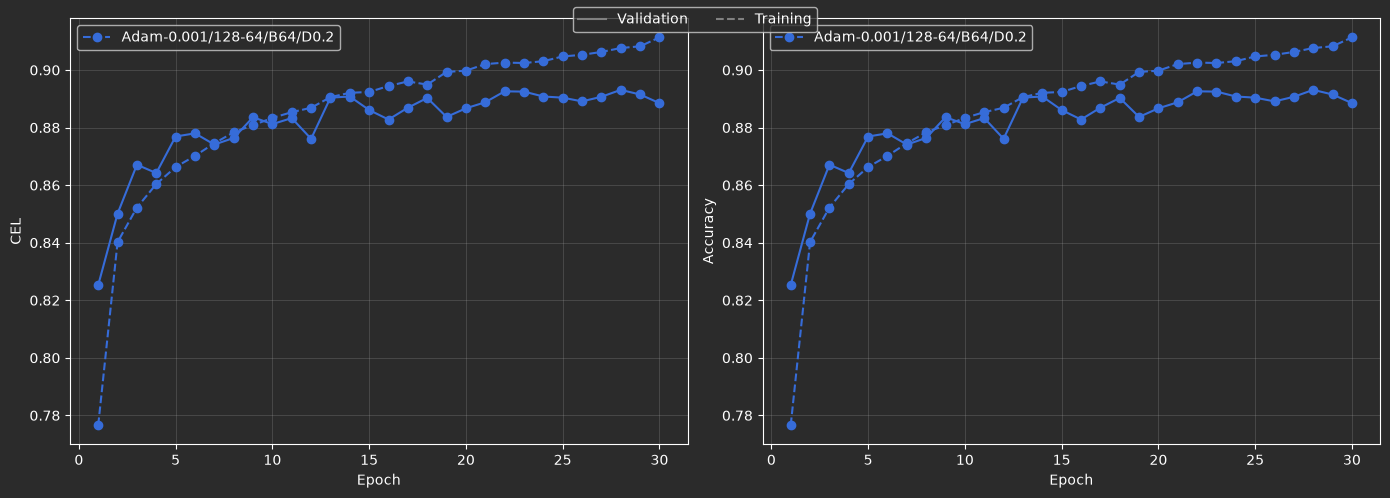

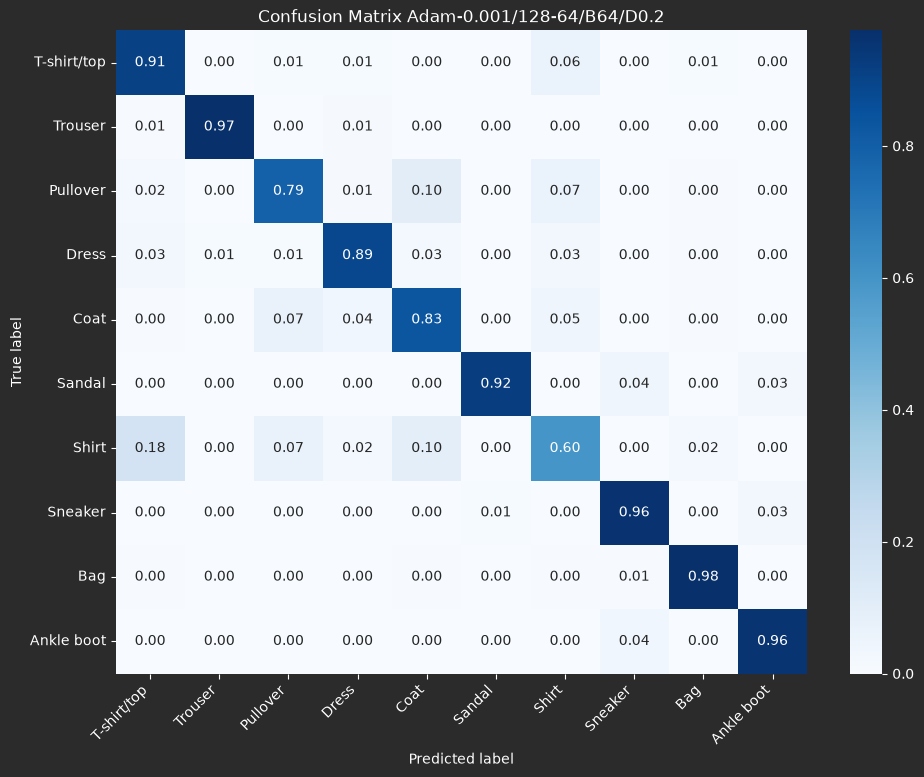


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 100
Training time: 127.07 seconds

Peak GPU memory: 37.69 MB

Test CEL: 0.34121
Test accuracy: 88.81%

----------------- Adam-0.001/128-64/B100/D0.2 -----------------


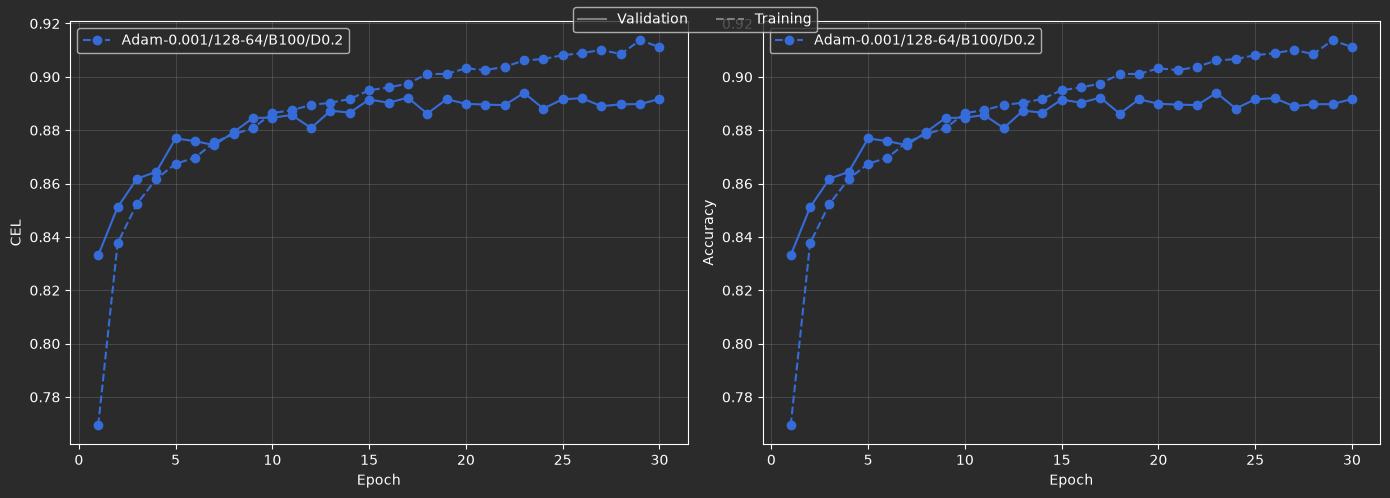

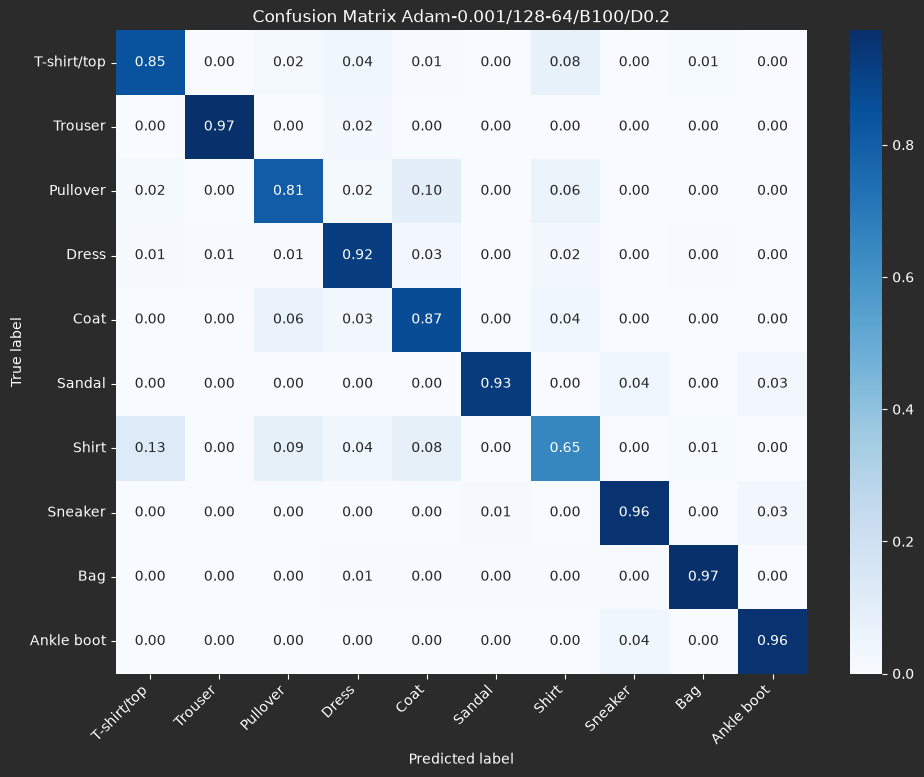


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 256
Training time: 114.19 seconds

Peak GPU memory: 39.78 MB

Test CEL: 0.33167
Test accuracy: 88.87%

----------------- Adam-0.001/128-64/B256/D0.2 -----------------


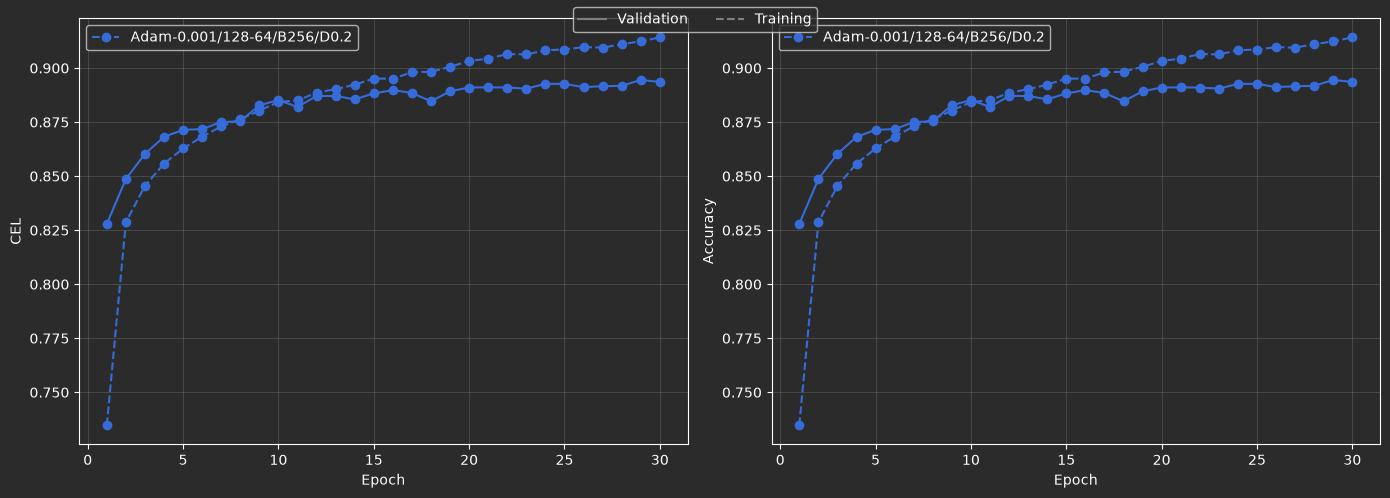

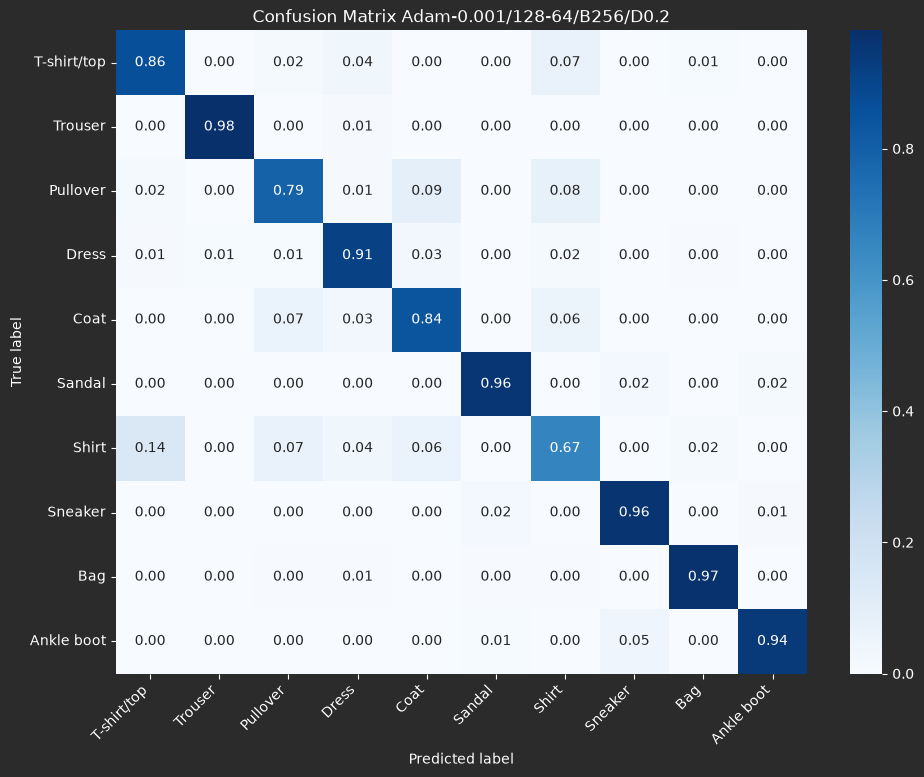


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 512
Training time: 112.04 seconds

Peak GPU memory: 42.66 MB

Test CEL: 0.32855
Test accuracy: 88.60%

----------------- Adam-0.001/128-64/B512/D0.2 -----------------


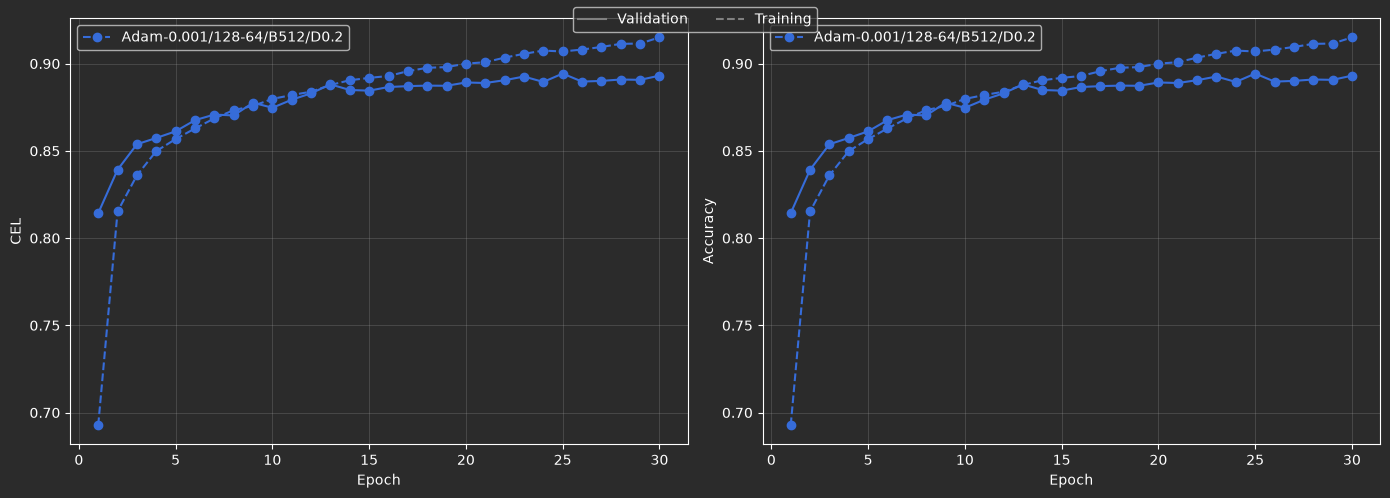

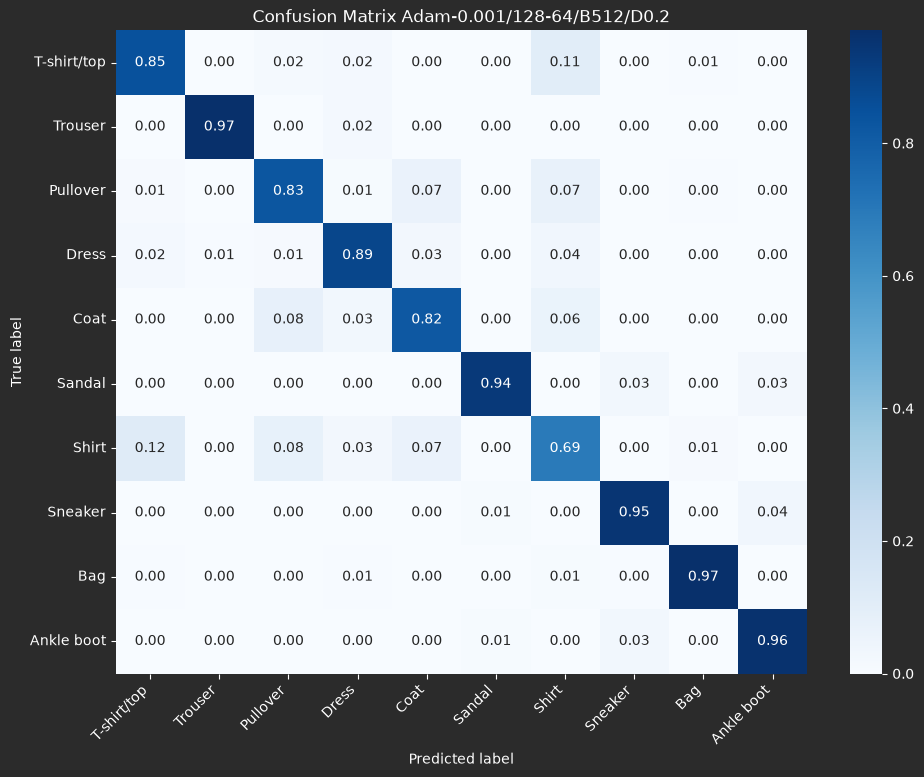


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 64
Training time: 133.67 seconds

Peak GPU memory: 42.71 MB

Test CEL: 0.51295
Test accuracy: 82.95%

----------------- Adam-0.01/128-64/B64/D0.2 -----------------


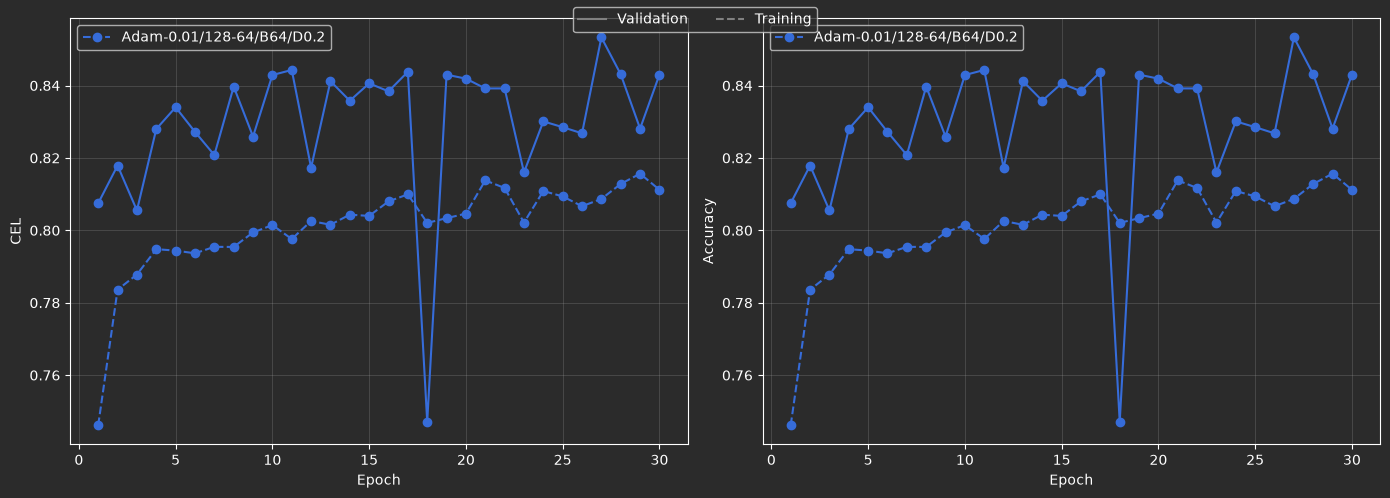

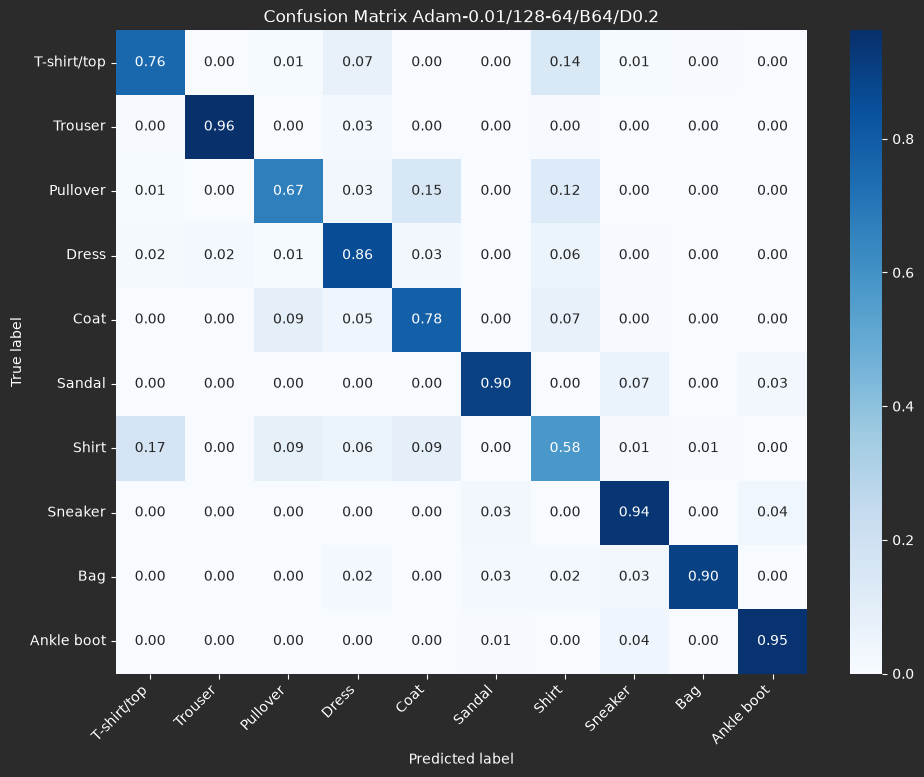


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 100
Training time: 127.90 seconds

Peak GPU memory: 44.38 MB

Test CEL: 0.45436
Test accuracy: 84.46%

----------------- Adam-0.01/128-64/B100/D0.2 -----------------


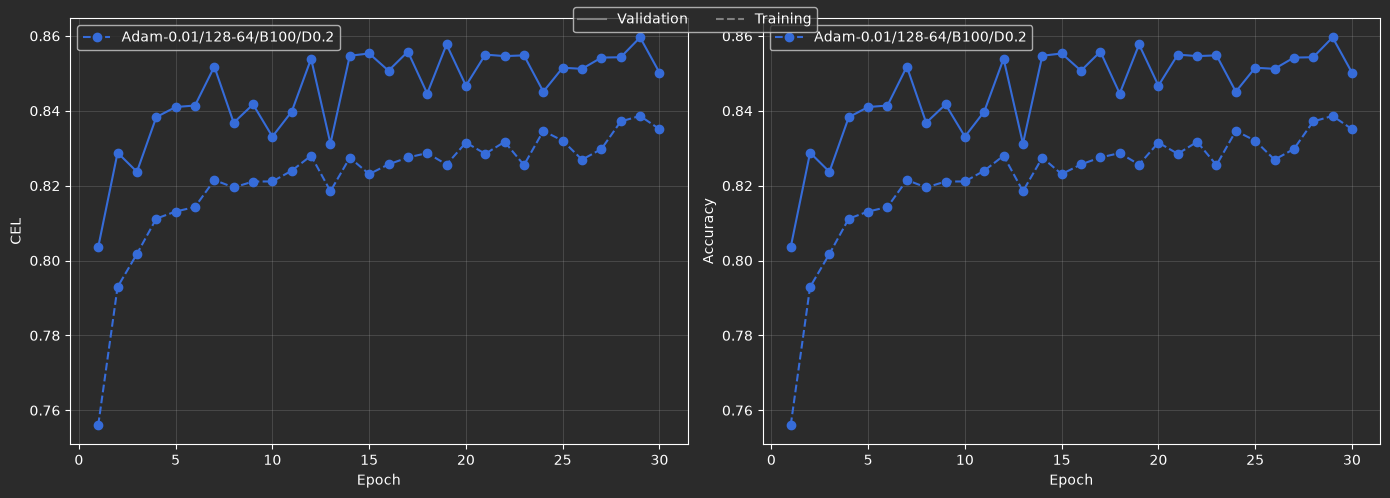

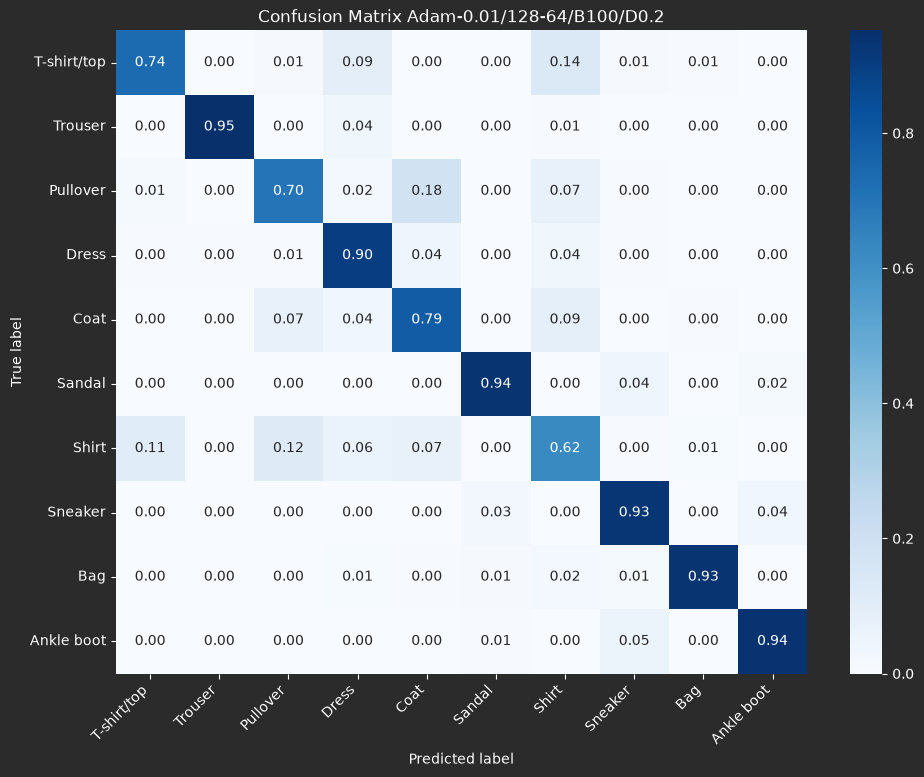


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 256
Training time: 113.48 seconds

Peak GPU memory: 46.47 MB

Test CEL: 0.42353
Test accuracy: 85.45%

----------------- Adam-0.01/128-64/B256/D0.2 -----------------


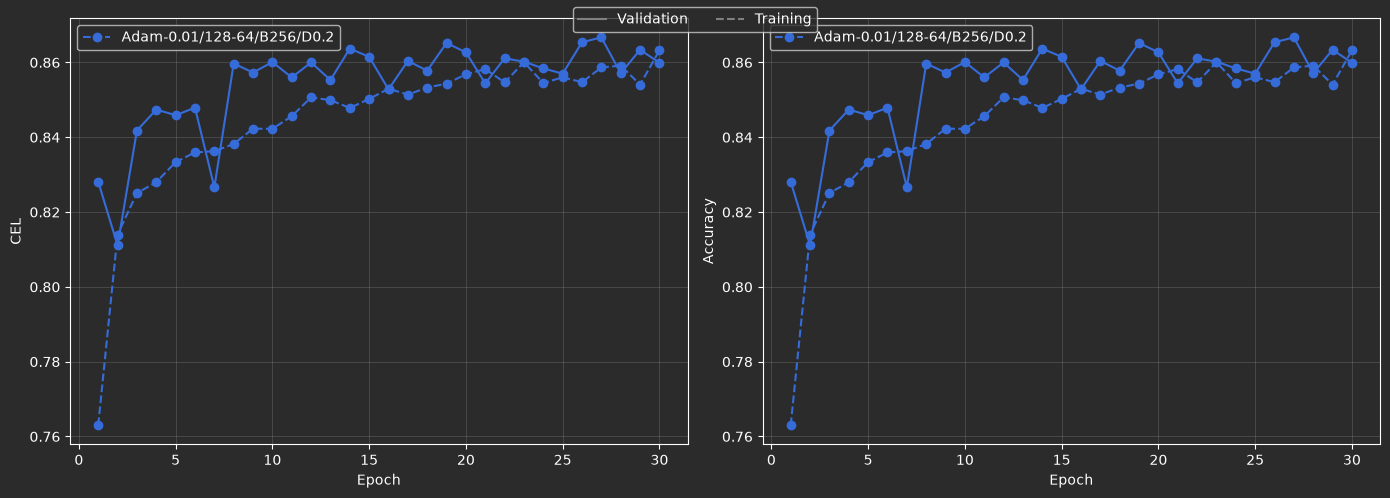

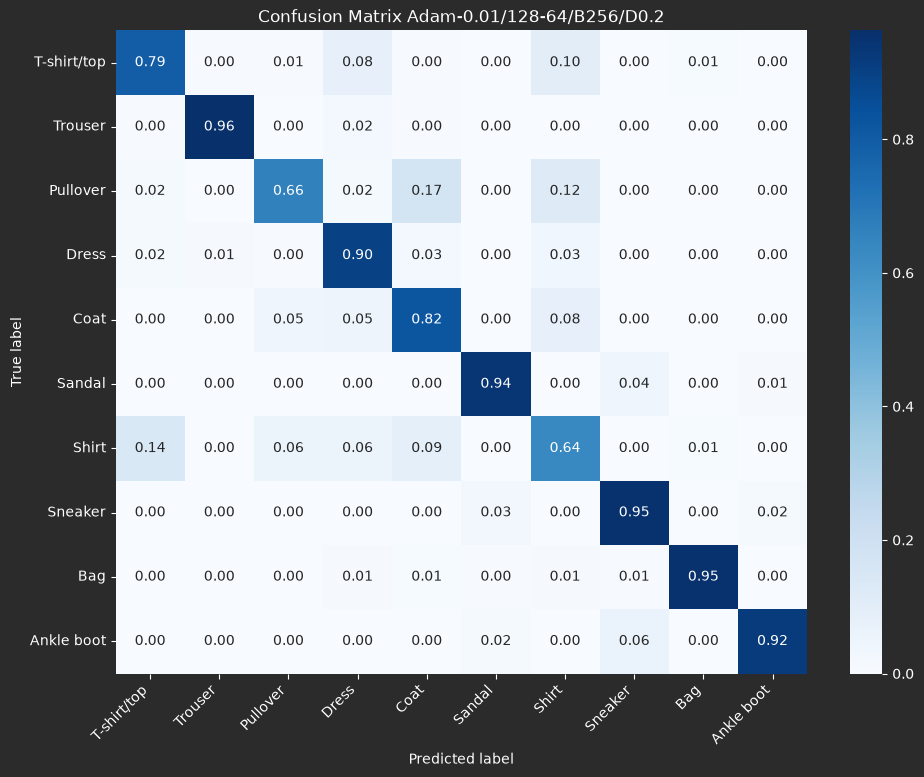


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 512
Training time: 112.79 seconds

Peak GPU memory: 49.35 MB

Test CEL: 0.37273
Test accuracy: 87.32%

----------------- Adam-0.01/128-64/B512/D0.2 -----------------


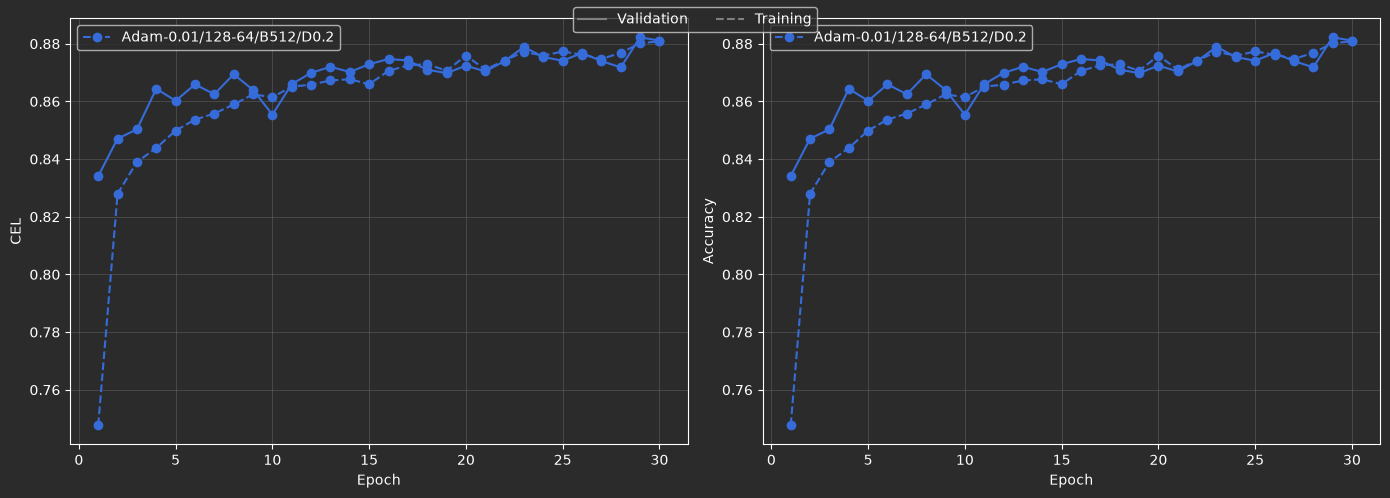

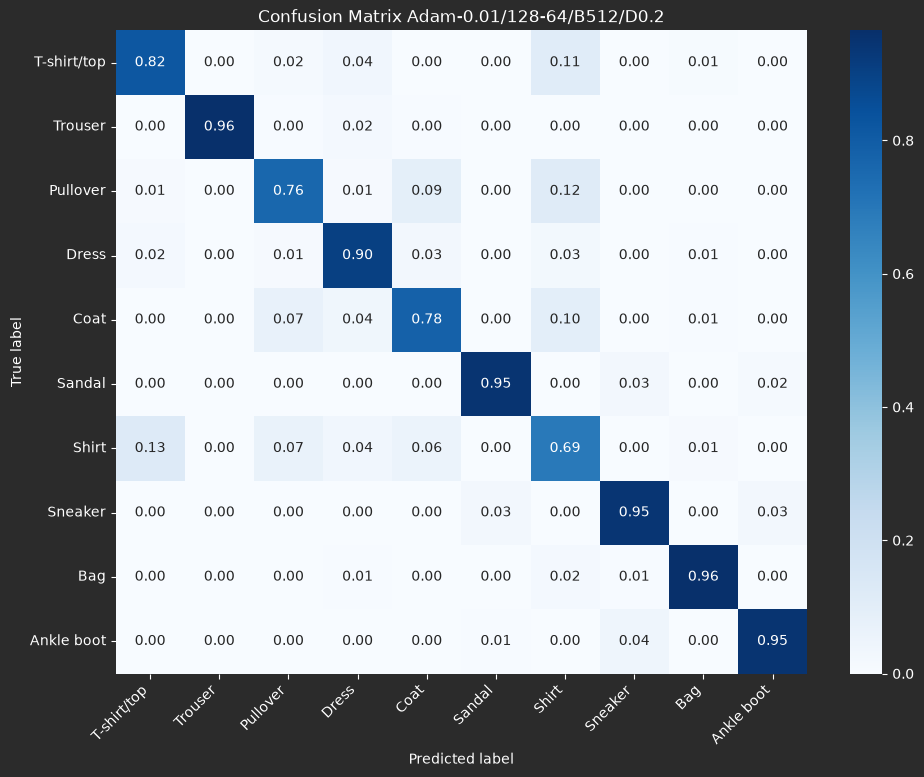

In [2]:
aftermath = pre_run(expies, data_loaders)


-----------------------------------Results TOGETHER:-----------------------------------


-----------------------------------GROUP: ('SGD', 0.001):-----------------------------------

----------------- SGD-0.001/128-64/B64/D0.2 -----------------
----------------- SGD-0.001/128-64/B100/D0.2 -----------------
----------------- SGD-0.001/128-64/B256/D0.2 -----------------
----------------- SGD-0.001/128-64/B512/D0.2 -----------------


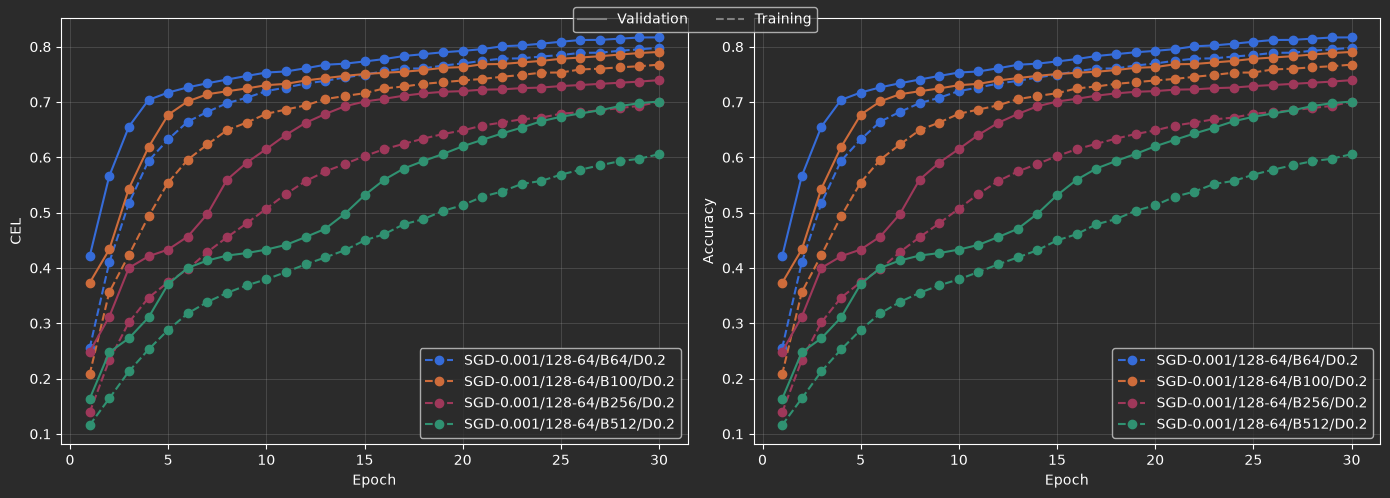

                           Train Loss Valid Loss Train Accu Valid Accu Test Accu Worst Class Worst Class Recall TV gap CM Deviation Training Time
SGD-0.001/128-64/B64/D0.2        0.57       0.52       0.80       0.82      0.81       Shirt               0.43  -0.02         0.79        134.28
SGD-0.001/128-64/B100/D0.2       0.64       0.58       0.77       0.79      0.78       Shirt               0.38  -0.02         0.97        123.45
SGD-0.001/128-64/B256/D0.2       0.84       0.75       0.70       0.74      0.74       Shirt               0.27  -0.04         1.36        114.61
SGD-0.001/128-64/B512/D0.2       1.16       1.06       0.61       0.70      0.70       Shirt               0.17  -0.10         1.78        111.88

--- Best experiments ---
Max Test Accu      -> SGD-0.001/128-64/B64/D0.2: 0.8065
Max Valid Accu     -> SGD-0.001/128-64/B64/D0.2: 0.8168
Best Worst-Class Recall -> SGD-0.001/128-64/B64/D0.2: Shirt (0.4350)
Min CM Deviation       -> SGD-0.001/128-64/B64/D0.2: 0.7883
Min

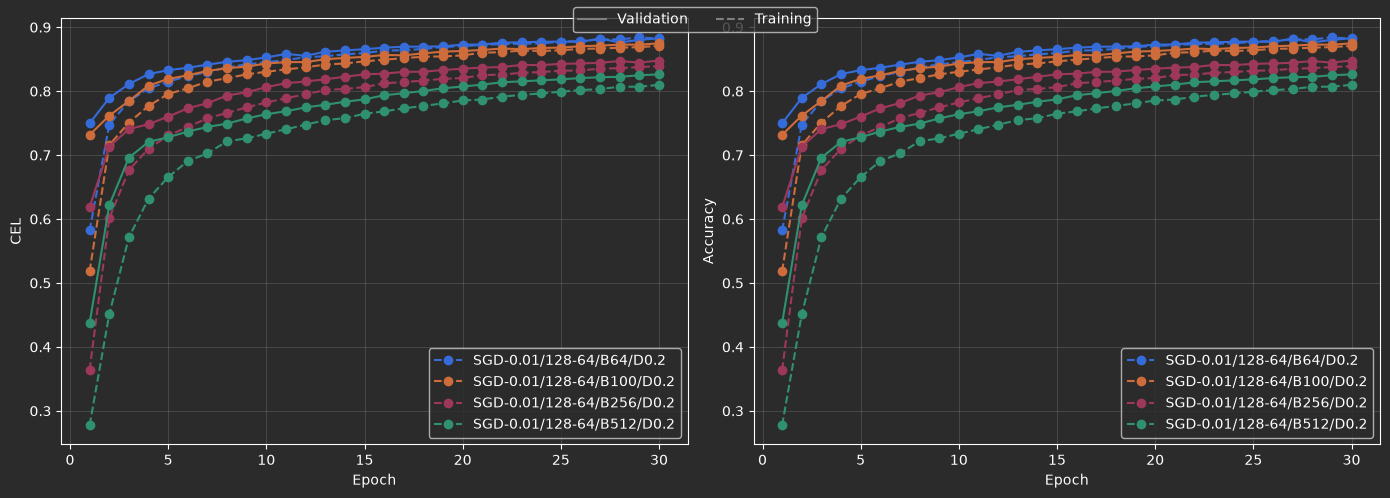

                          Train Loss Valid Loss Train Accu Valid Accu Test Accu Worst Class Worst Class Recall TV gap CM Deviation Training Time
SGD-0.01/128-64/B64/D0.2        0.33       0.33       0.88       0.88      0.87       Shirt               0.63  -0.00         0.35        130.81
SGD-0.01/128-64/B100/D0.2       0.36       0.35       0.87       0.87      0.86       Shirt               0.62  -0.00         0.39        123.52
SGD-0.01/128-64/B256/D0.2       0.45       0.42       0.84       0.85      0.84       Shirt               0.54  -0.01         0.55        113.36
SGD-0.01/128-64/B512/D0.2       0.54       0.49       0.81       0.83      0.81       Shirt               0.46  -0.02         0.72         86.58

--- Best experiments ---
Max Test Accu      -> SGD-0.01/128-64/B64/D0.2: 0.8725
Max Valid Accu     -> SGD-0.01/128-64/B64/D0.2: 0.8827
Best Worst-Class Recall -> SGD-0.01/128-64/B64/D0.2: Shirt (0.6340)
Min CM Deviation       -> SGD-0.01/128-64/B64/D0.2: 0.3538
Min Training

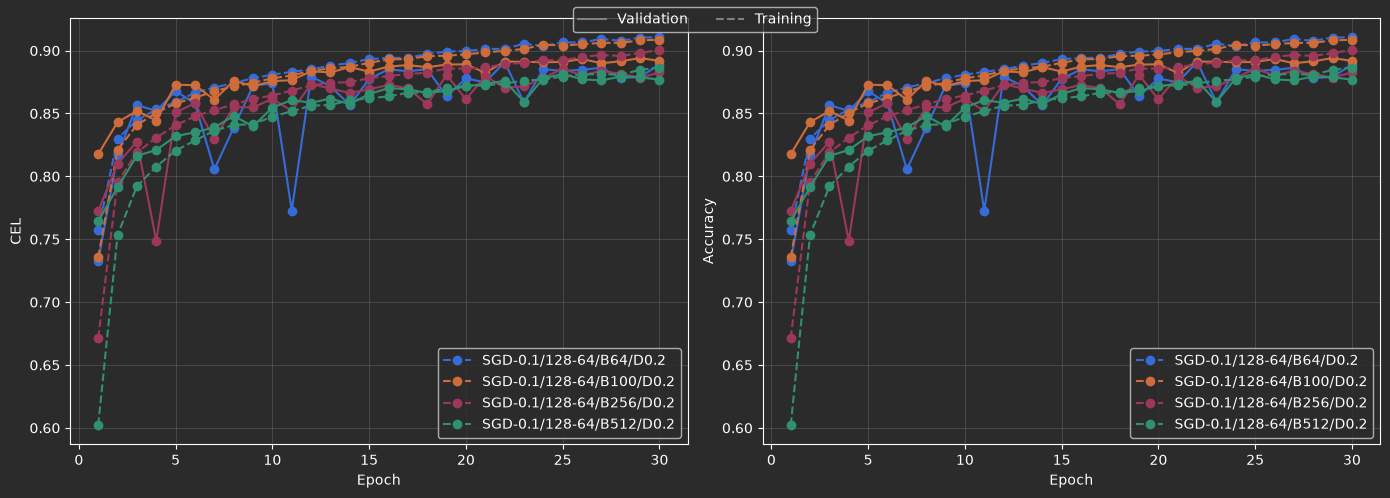

                         Train Loss Valid Loss Train Accu Valid Accu Test Accu Worst Class Worst Class Recall TV gap CM Deviation Training Time
SGD-0.1/128-64/B64/D0.2        0.24       0.32       0.91       0.89      0.88       Shirt               0.63   0.02         0.32        131.36
SGD-0.1/128-64/B100/D0.2       0.24       0.30       0.91       0.89      0.89       Shirt               0.71   0.02         0.27        125.54
SGD-0.1/128-64/B256/D0.2       0.28       0.33       0.90       0.88      0.87       Shirt               0.58   0.02         0.41        112.89
SGD-0.1/128-64/B512/D0.2       0.32       0.33       0.89       0.88      0.86    Pullover               0.67   0.01         0.40        111.86

--- Best experiments ---
Max Test Accu      -> SGD-0.1/128-64/B100/D0.2: 0.8865
Max Valid Accu     -> SGD-0.1/128-64/B100/D0.2: 0.8918
Best Worst-Class Recall -> SGD-0.1/128-64/B100/D0.2: Shirt (0.7090)
Min CM Deviation       -> SGD-0.1/128-64/B100/D0.2: 0.2727
Min Training Time

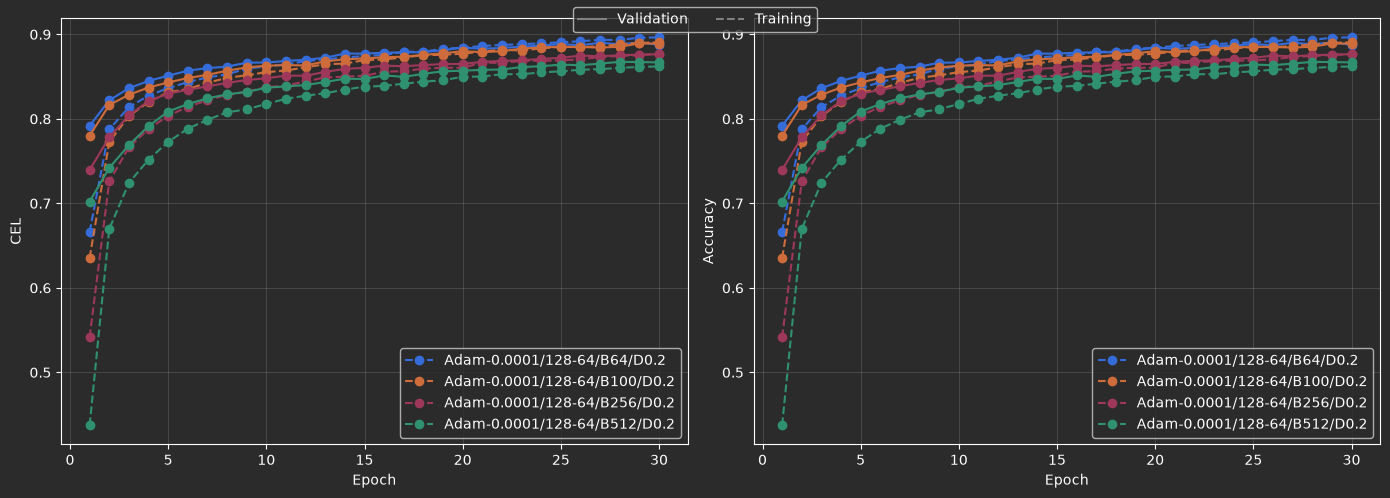

                             Train Loss Valid Loss Train Accu Valid Accu Test Accu Worst Class Worst Class Recall TV gap CM Deviation Training Time
Adam-0.0001/128-64/B64/D0.2        0.29       0.31       0.90       0.89      0.88       Shirt               0.65   0.01         0.31        134.14
Adam-0.0001/128-64/B100/D0.2       0.30       0.32       0.89       0.89      0.88       Shirt               0.66   0.00         0.32        126.44
Adam-0.0001/128-64/B256/D0.2       0.35       0.34       0.88       0.88      0.87       Shirt               0.66   0.00         0.36        115.80
Adam-0.0001/128-64/B512/D0.2       0.38       0.37       0.86       0.87      0.86       Shirt               0.61  -0.00         0.42        113.50

--- Best experiments ---
Max Test Accu      -> Adam-0.0001/128-64/B64/D0.2: 0.8814
Max Valid Accu     -> Adam-0.0001/128-64/B100/D0.2: 0.8890
Best Worst-Class Recall -> Adam-0.0001/128-64/B100/D0.2: Shirt (0.6630)
Min CM Deviation       -> Adam-0.0001/128-64/

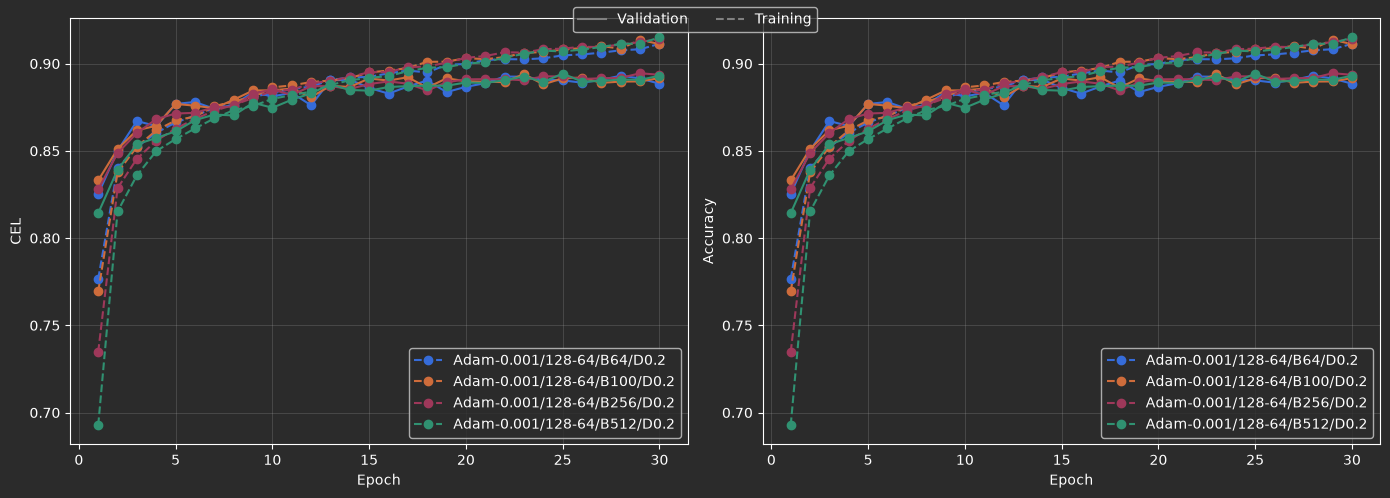

                            Train Loss Valid Loss Train Accu Valid Accu Test Accu Worst Class Worst Class Recall TV gap CM Deviation Training Time
Adam-0.001/128-64/B64/D0.2        0.24       0.33       0.91       0.89      0.88       Shirt               0.60   0.02         0.35        133.72
Adam-0.001/128-64/B100/D0.2       0.23       0.32       0.91       0.89      0.89       Shirt               0.65   0.02         0.28        127.07
Adam-0.001/128-64/B256/D0.2       0.23       0.31       0.91       0.89      0.89       Shirt               0.67   0.02         0.28        114.19
Adam-0.001/128-64/B512/D0.2       0.23       0.30       0.92       0.89      0.89       Shirt               0.69   0.02         0.27        112.04

--- Best experiments ---
Max Test Accu      -> Adam-0.001/128-64/B256/D0.2: 0.8887
Max Valid Accu     -> Adam-0.001/128-64/B256/D0.2: 0.8936
Best Worst-Class Recall -> Adam-0.001/128-64/B512/D0.2: Shirt (0.6950)
Min CM Deviation       -> Adam-0.001/128-64/B512/D0.

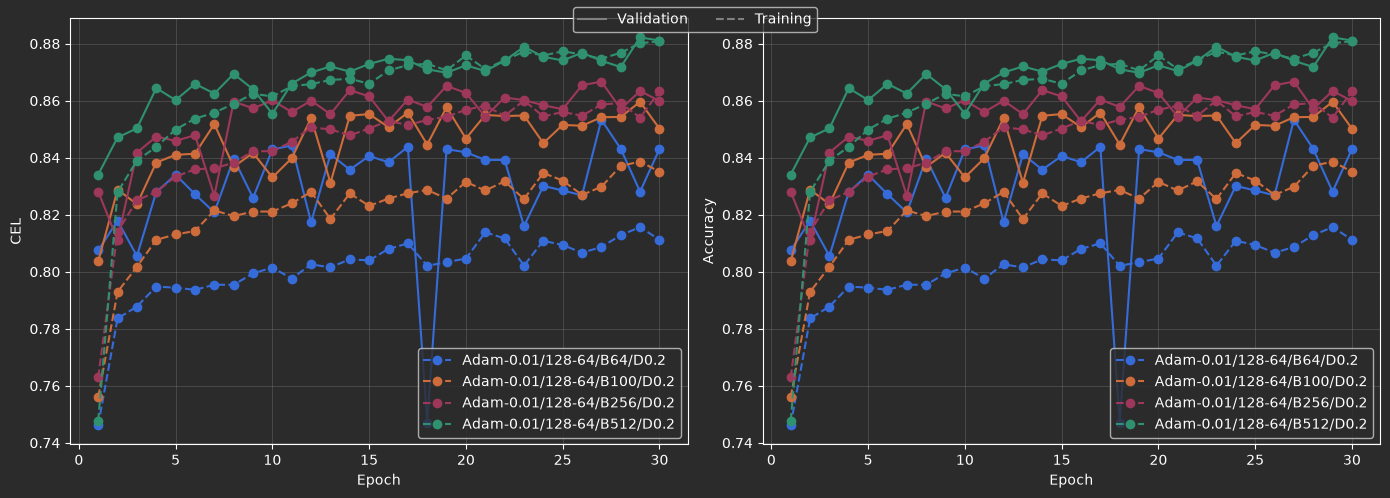

                           Train Loss Valid Loss Train Accu Valid Accu Test Accu Worst Class Worst Class Recall TV gap CM Deviation Training Time
Adam-0.01/128-64/B64/D0.2        0.55       0.52       0.81       0.84      0.83       Shirt               0.58  -0.03         0.59        133.67
Adam-0.01/128-64/B100/D0.2       0.48       0.44       0.84       0.85      0.84       Shirt               0.62  -0.02         0.50        127.90
Adam-0.01/128-64/B256/D0.2       0.38       0.40       0.86       0.86      0.85       Shirt               0.64   0.00         0.47        113.48
Adam-0.01/128-64/B512/D0.2       0.33       0.35       0.88       0.88      0.87       Shirt               0.69  -0.00         0.34        112.79

--- Best experiments ---
Max Test Accu      -> Adam-0.01/128-64/B512/D0.2: 0.8732
Max Valid Accu     -> Adam-0.01/128-64/B512/D0.2: 0.8811
Best Worst-Class Recall -> Adam-0.01/128-64/B512/D0.2: Shirt (0.6940)
Min CM Deviation       -> Adam-0.01/128-64/B512/D0.2: 0.3378

In [3]:
viewAftermath(aftermath)

import winsound
for _ in range(14):
    winsound.MessageBeep(winsound.MB_ICONEXCLAMATION)
    time.sleep(0.5)